# Citi Bike project, part 3: charts for the slides

Group 01: William Challma, Thomas Savazzi, Alessandro Simone

The analysis notebook (`2_Analysis`) only draws the standard charts of the course. For the presentation and the report we wanted cleaner charts, in the colours of the Citi Bike logo and at the size they take on the slides. For this notebook we were helped by an AI assistant (LLM), mainly for the matplotlib formatting: colours, labels, annotations and layout. The data, the models and the settings are the same as in the analysis notebook (same variables, same `random_state`), so the numbers on the charts are the numbers of the analysis.

The notebook reads the csv files of the `2_Analysis` folder and saves the charts in the `charts` folder next to it.

In [ ]:
# Google Colab
# !pip install gensim mlxtend
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.dates as mdates
import json
import os

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn import metrics
from sklearn.metrics import roc_curve, auc, confusion_matrix, precision_recall_curve
from imblearn.over_sampling import SMOTE, RandomOverSampler
import xgboost as xgb

import warnings
warnings.filterwarnings('ignore')

os.makedirs('charts', exist_ok=True)

## Style: colours of the Citi Bike logo

In [ ]:
NAVY = '#263571'
BLUE = '#39A2E1'
MUTED = '#8C9BC0'
LIGHT = '#CDD2DA'
TINT = '#EAF4FB'
INK = '#1E2640'
GREY = '#7A8296'
BLUE_D = '#1F86C8'

plt.rcParams.update({'font.family': 'Arial', 'font.size': 11, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
                     'axes.titlelocation': 'left', 'axes.titlecolor': INK, 'axes.titlepad': 10,
                     'axes.edgecolor': LIGHT, 'axes.labelcolor': GREY, 'axes.labelsize': 10.5,
                     'xtick.color': GREY, 'ytick.color': GREY, 'xtick.labelsize': 10, 'ytick.labelsize': 10,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False,
                     'legend.frameon': False, 'legend.fontsize': 10, 'figure.dpi': 110})

blues = LinearSegmentedColormap.from_list('citi', ['#FFFFFF', BLUE, NAVY])
hour_ticks = range(0, 24, 3)
hour_labels = [f'{h}:00' for h in hour_ticks]
numbers = {}   # numbers quoted in the slides

def save(fig, name):
    fig.savefig('charts/' + name + '.png', dpi=220)
    plt.show()

## Data and segments

In [ ]:
DATA = '../../2_Analysis/'   # csv files of the analysis folder

stations = pd.read_csv(DATA + 'stations.csv')
station_day = pd.read_csv(DATA + 'station_day.csv', parse_dates=['date'])
trips = pd.read_csv(DATA + 'trips_sample.csv', parse_dates=['started_at', 'date'])
reviews = pd.read_csv(DATA + 'reviews_clean.csv')

dep_cols = ['dep_' + str(h) for h in range(24)]
arr_cols = ['arr_' + str(h) for h in range(24)]
X_scaled = StandardScaler().fit_transform(stations[dep_cols + arr_cols])
pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)
stations['cluster'] = KMeans(n_clusters=4, random_state=42, n_init=10).fit_predict(X_pca)
cluster_names = {0: 'Work (morning arrivals)', 1: 'Residential (morning departures)', 2: 'Busy mixed', 3: 'Low demand / leisure'}
stations['segment'] = stations['cluster'].map(cluster_names)
short = {'Work (morning arrivals)': 'Work', 'Residential (morning departures)': 'Residential', 'Busy mixed': 'Busy mixed', 'Low demand / leisure': 'Low demand'}
stations['seg'] = stations['segment'].map(short)
station_day = station_day.merge(stations[['station_name', 'segment']], on='station_name')
station_day['seg'] = station_day['segment'].map(short)

seg_order = ['Residential', 'Work', 'Busy mixed', 'Low demand']
seg_colors = {'Residential': BLUE, 'Work': NAVY, 'Busy mixed': MUTED, 'Low demand': LIGHT}
stations['seg'].value_counts()

seg
Busy mixed     842
Residential    628
Low demand     511
Work           337
Name: count, dtype: int64

## 1. The problem: when are stations empty or full?

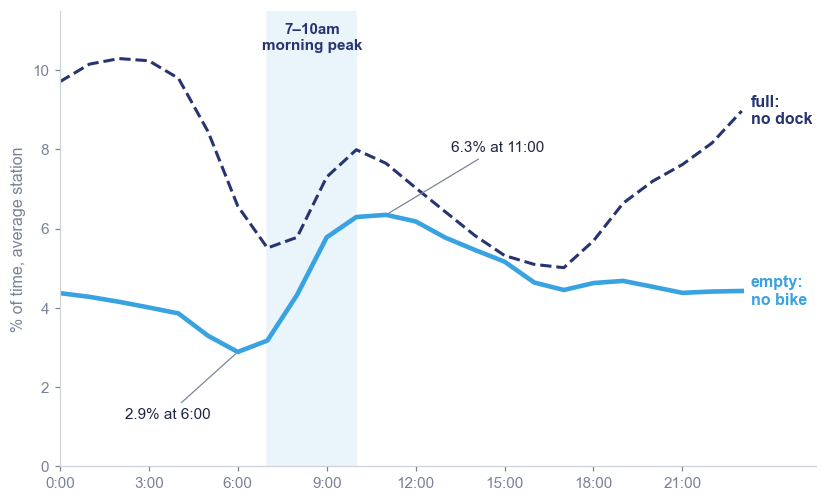

In [ ]:
empty = stations[['empty_' + str(h) for h in range(24)]].mean().values
full = stations[['full_' + str(h) for h in range(24)]].mean().values

fig, ax = plt.subplots(figsize=(7.4, 4.45), layout='constrained')
ax.axvspan(7, 10, color=TINT)
ax.text(8.5, 11.2, '7–10am\nmorning peak', ha='center', va='top', color=NAVY, fontsize=10, fontweight='bold')
ax.plot(range(24), empty, color=BLUE, lw=3)
ax.plot(range(24), full, color=NAVY, lw=2, ls='--')
ax.text(23.3, empty[23], 'empty:\nno bike', color=BLUE, fontsize=10.5, fontweight='bold', va='center')
ax.text(23.3, full[23], 'full:\nno dock', color=NAVY, fontsize=10.5, fontweight='bold', va='center')
h = int(np.argmax(empty))
ax.annotate(f'{empty[h]:.1f}% at {h}:00', (h, empty[h]), (h + 2.2, empty[h] + 1.6), color=INK, fontsize=10,
            arrowprops=dict(arrowstyle='-', color=GREY, lw=0.8))
ax.annotate(f'{empty[6]:.1f}% at 6:00', (6, empty[6]), (2.2, 1.2), color=INK, fontsize=10, arrowprops=dict(arrowstyle='-', color=GREY, lw=0.8))
ax.set_xlim(0, 25.5)
ax.set_ylim(0, 11.5)
ax.set_xticks(hour_ticks, hour_labels)
ax.set_ylabel('% of time, average station')
save(fig, 'problem_hourly')
numbers['empty_peak'] = [h, round(empty[h], 1)]
numbers['empty_6am'] = round(empty[6], 1)

## 2. Data overview

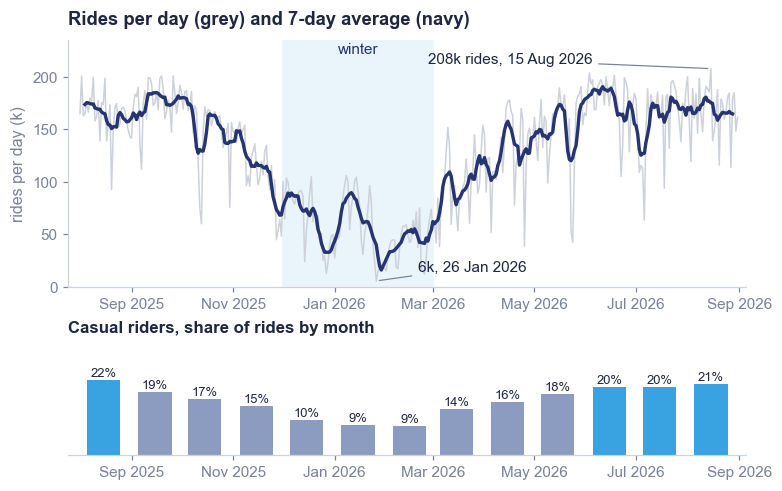

{'empty_peak': [11, np.float64(6.3)], 'empty_6am': np.float64(2.9), 'rides_max': ['2026-08-15', 207734], 'rides_min': ['2026-01-26', 5749], 'rides_per_day': 128159}


In [ ]:
# rides per day from the 2,318 stations, and casual share by month (from the sample)
daily = station_day.groupby('date').agg(rides=('departures', 'sum'), tavg=('tavg', 'first'), prcp=('prcp', 'first'), is_weekend=('is_weekend', 'first'))
daily['avg7'] = daily['rides'].rolling(7, center=True).mean()
casual_month = trips.groupby('month')['member_casual'].apply(lambda s: (s == 'casual').mean() * 100)

fig, axes = plt.subplots(2, 1, figsize=(7.0, 4.35), height_ratios=[3, 1.3], layout='constrained')
ax = axes[0]
ax.axvspan(pd.Timestamp('2025-12-01'), pd.Timestamp('2026-03-01'), color=TINT)
ax.plot(daily.index, daily['rides'] / 1000, color=LIGHT, lw=1)
ax.plot(daily.index, daily['avg7'] / 1000, color=NAVY, lw=2.2)
top, low = daily['rides'].idxmax(), daily['rides'].idxmin()
ax.annotate(f"{daily.loc[top, 'rides'] / 1000:.0f}k rides, {top:%d %b %Y}", (top, daily.loc[top, 'rides'] / 1000), (top - pd.Timedelta(days=170), 212),
            fontsize=10, color=INK, arrowprops=dict(arrowstyle='-', color=GREY, lw=0.8))
ax.annotate(f"{daily.loc[low, 'rides'] / 1000:.0f}k, {low:%d %b %Y}", (low, daily.loc[low, 'rides'] / 1000), (low + pd.Timedelta(days=25), 15),
            fontsize=10, color=INK, arrowprops=dict(arrowstyle='-', color=GREY, lw=0.8))
ax.text(pd.Timestamp('2026-01-15'), 222, 'winter', ha='center', color=NAVY, fontsize=10)
ax.set_ylim(0, 235)
ax.set_ylabel('rides per day (k)')
ax.set_title('Rides per day (grey) and 7-day average (navy)')
ax = axes[1]
x = pd.to_datetime(casual_month.index + '-15')
ax.bar(x, casual_month.values, width=20, color=[BLUE if v >= 20 else MUTED for v in casual_month.values])
for xi, v in zip(x, casual_month.values):
    ax.text(xi, v + 1, f'{v:.0f}%', ha='center', fontsize=8.5, color=INK)
ax.set_ylim(0, 32)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_title('Casual riders, share of rides by month', fontsize=11)
for a in axes:
    a.set_xlim(pd.Timestamp('2025-07-25'), pd.Timestamp('2026-09-05'))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
save(fig, 'data_daily')
numbers['rides_max'] = [str(top.date()), int(daily.loc[top, 'rides'])]
numbers['rides_min'] = [str(low.date()), int(daily.loc[low, 'rides'])]
numbers['rides_per_day'] = int(daily['rides'].mean())
print(numbers)

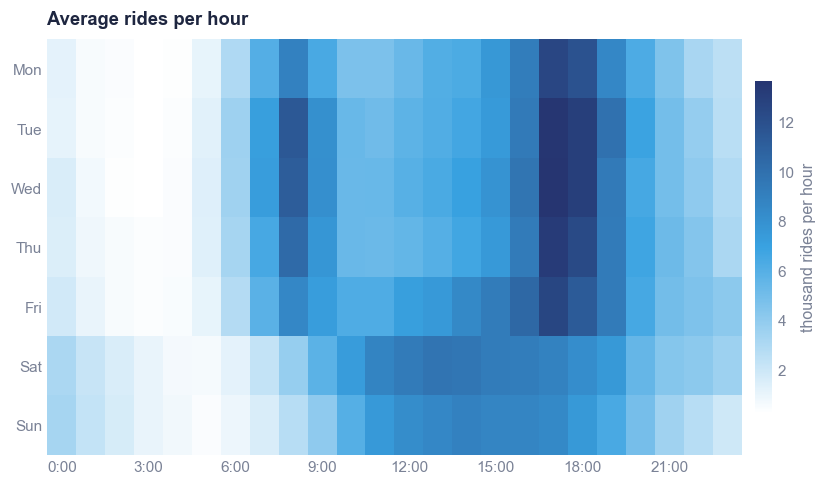

In [ ]:
# when: average rides per hour, day of the week x hour (sample x 250 = whole population)
n_days = trips.groupby('weekday')['date'].nunique()
grid = trips.groupby(['weekday', 'hour']).size().unstack() * 250
grid = grid.div(n_days, axis=0)

fig, ax = plt.subplots(figsize=(7.4, 4.3), layout='constrained')
im = ax.imshow(grid.values / 1000, cmap=blues, aspect='auto')
ax.set_yticks(range(7), ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])
ax.set_xticks(hour_ticks, hour_labels)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
cb.outline.set_visible(False)
cb.ax.tick_params(length=0)
cb.set_label('thousand rides per hour', color=GREY)
ax.set_title('Average rides per hour')
save(fig, 'data_heatmap')
numbers['peak_hour_rides'] = int(grid.values.max())

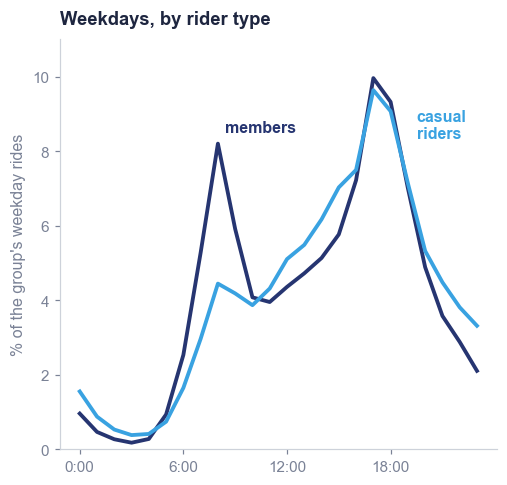

In [ ]:
# who: share of each group's weekday rides by hour
wk = trips[trips['is_weekend'] == False]
share = pd.crosstab(wk['hour'], wk['member_casual'], normalize='columns') * 100

fig, ax = plt.subplots(figsize=(4.5, 4.3), layout='constrained')
ax.plot(share.index, share['member'], color=NAVY, lw=2.5)
ax.plot(share.index, share['casual'], color=BLUE, lw=2.5)
ax.text(8.4, share.loc[8, 'member'] + 0.3, 'members', color=NAVY, fontsize=10.5, fontweight='bold')
ax.text(19.5, share.loc[19, 'casual'] + 1.2, 'casual\nriders', color=BLUE, fontsize=10.5, fontweight='bold')
ax.set_xticks(range(0, 24, 6), [f'{h}:00' for h in range(0, 24, 6)])
ax.set_ylabel('% of the group\'s weekday rides')
ax.set_ylim(0, 11)
ax.set_title('Weekdays, by rider type')
save(fig, 'data_riders_hour')

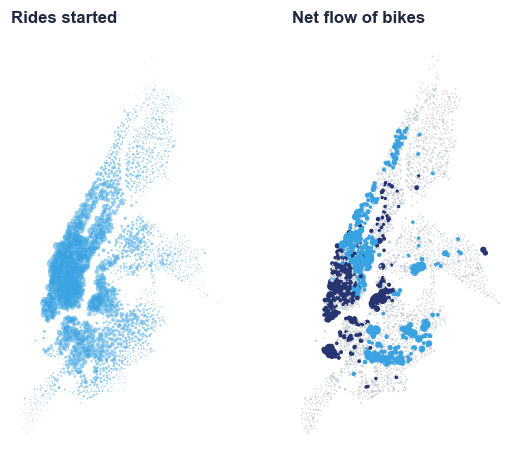

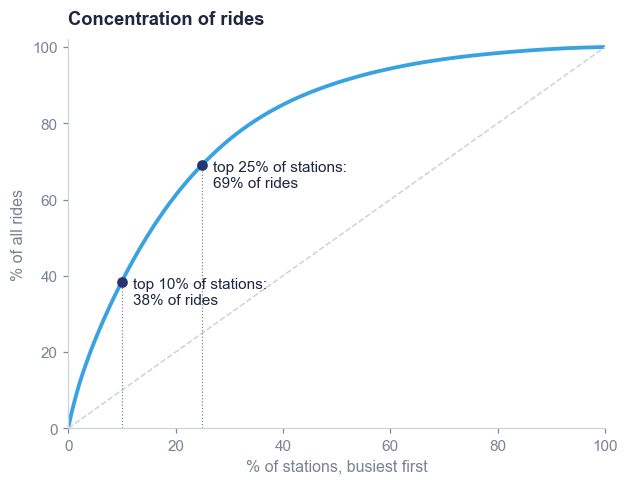

{'empty_peak': [11, np.float64(6.3)], 'empty_6am': np.float64(2.9), 'rides_max': ['2026-08-15', 207734], 'rides_min': ['2026-01-26', 5749], 'rides_per_day': 128159, 'peak_hour_rides': 13651, 'top10_share': np.float64(38.5), 'top25_share': np.float64(69.2), 'net_flow_lose': 277, 'net_flow_gain': 265}


In [ ]:
# where: departures and net flow per station, concentration of rides
fig, axes = plt.subplots(1, 2, figsize=(5.1, 4.1), layout='constrained')
ax = axes[0]
ax.scatter(stations['lng'], stations['lat'], s=stations['departures'] / 4000, color=BLUE, alpha=0.55, linewidths=0)
ax.set_title('Rides started', fontsize=11)
ax = axes[1]
nf = stations['net_flow']
col = np.where(nf < -300, BLUE, np.where(nf > 300, NAVY, LIGHT))
ax.scatter(stations['lng'], stations['lat'], s=np.clip(abs(nf) / 60, 1, 40), color=col, linewidths=0)
ax.set_title('Net flow of bikes', fontsize=11)
for a in axes:
    a.set_aspect(1.32)
    a.axis('off')
save(fig, 'data_maps')

dep = stations['departures'].sort_values(ascending=False).values
cum = dep.cumsum() / dep.sum() * 100
x = np.arange(1, len(dep) + 1) / len(dep) * 100
fig, ax = plt.subplots(figsize=(5.6, 4.3), layout='constrained')
ax.plot(x, cum, color=BLUE, lw=2.5)
ax.plot([0, 100], [0, 100], color=LIGHT, ls='--', lw=1)
for p in [10, 25]:
    v = cum[int(len(dep) * p / 100) - 1]
    ax.plot([p, p], [0, v], color=GREY, lw=0.8, ls=':')
    ax.plot(p, v, 'o', color=NAVY)
    ax.text(p + 2, v - 6, f'top {p}% of stations:\n{v:.0f}% of rides', fontsize=10, color=INK)
    numbers[f'top{p}_share'] = round(v, 1)
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.set_xlabel('% of stations, busiest first')
ax.set_ylabel('% of all rides')
ax.set_title('Concentration of rides')
save(fig, 'data_lorenz')
numbers['net_flow_lose'] = int((nf < -300).sum())
numbers['net_flow_gain'] = int((nf > 300).sum())
print(numbers)

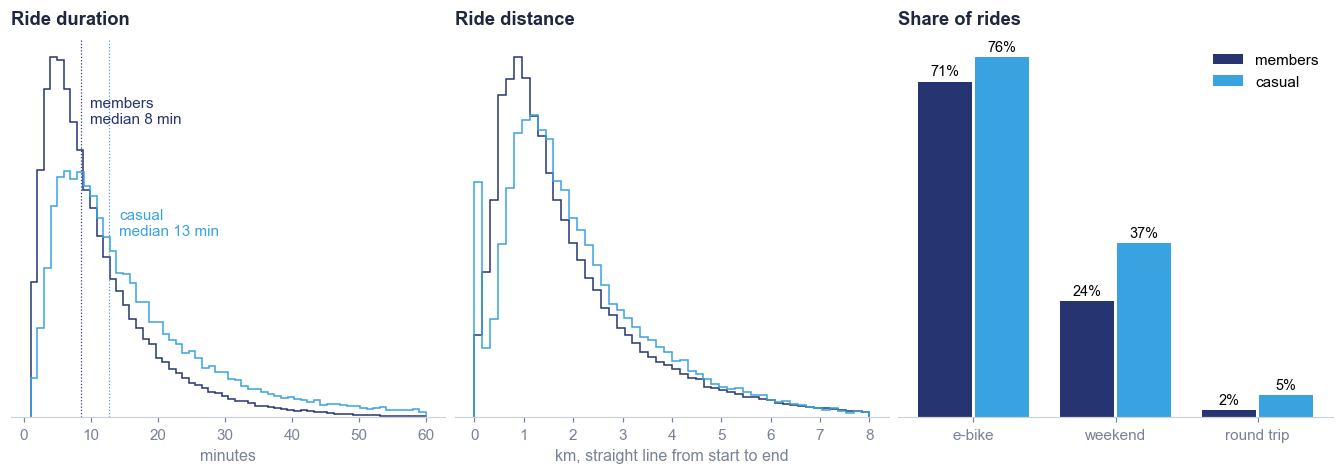

,e-bike,weekend,round trip
member_casual,,,
member,70.8,24.4,1.5
casual,75.9,36.7,4.7


In [ ]:
# what a ride looks like
fig, axes = plt.subplots(1, 3, figsize=(12.1, 4.2), layout='constrained')
ax = axes[0]
for who, c in [('member', NAVY), ('casual', BLUE)]:
    d = trips[(trips['member_casual'] == who) & (trips['duration_min'] < 60)]['duration_min']
    ax.hist(d, bins=60, density=True, histtype='step', lw=2, color=c)
    m = trips[trips['member_casual'] == who]['duration_min'].median()
    ax.axvline(m, color=c, lw=0.8, ls=':')
    numbers['median_duration_' + who] = round(m, 1)
ax.text(numbers['median_duration_member'] + 1.5, 0.068, f"members\nmedian {numbers['median_duration_member']:.0f} min", color=NAVY, fontsize=10)
ax.text(numbers['median_duration_casual'] + 1.5, 0.042, f"casual\nmedian {numbers['median_duration_casual']:.0f} min", color=BLUE, fontsize=10)
ax.set_xlabel('minutes')
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_title('Ride duration')
ax = axes[1]
for who, c in [('member', NAVY), ('casual', BLUE)]:
    d = trips[(trips['member_casual'] == who) & (trips['distance_km'] < 8)]['distance_km']
    ax.hist(d, bins=50, density=True, histtype='step', lw=2, color=c)
    numbers['median_km_' + who] = round(trips[trips['member_casual'] == who]['distance_km'].median(), 2)
ax.set_xlabel('km, straight line from start to end')
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_title('Ride distance')
ax = axes[2]
tab = pd.DataFrame({'e-bike': trips.groupby('member_casual')['rideable_type'].apply(lambda s: (s == 'electric_bike').mean() * 100),
                    'weekend': trips.groupby('member_casual')['is_weekend'].mean() * 100,
                    'round trip': trips.groupby('member_casual')['round_trip'].mean() * 100}).loc[['member', 'casual']]
xx = np.arange(3)
b1 = ax.bar(xx - 0.2, tab.loc['member'], 0.38, color=NAVY, label='members')
b2 = ax.bar(xx + 0.2, tab.loc['casual'], 0.38, color=BLUE, label='casual')
ax.bar_label(b1, fmt='%.0f%%', fontsize=9.5, padding=2)
ax.bar_label(b2, fmt='%.0f%%', fontsize=9.5, padding=2)
ax.set_xticks(xx, tab.columns)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.legend(loc='upper right')
ax.set_title('Share of rides')
save(fig, 'data_trips')
tab.round(1)

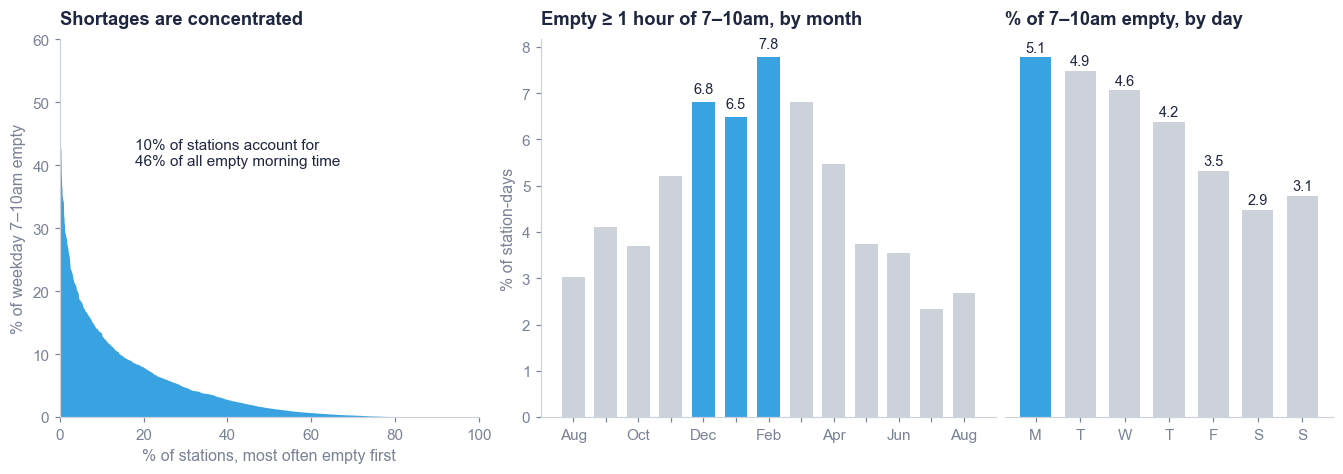

{'empty_peak': [11, np.float64(6.3)], 'empty_6am': np.float64(2.9), 'rides_max': ['2026-08-15', 207734], 'rides_min': ['2026-01-26', 5749], 'rides_per_day': 128159, 'peak_hour_rides': 13651, 'top10_share': np.float64(38.5), 'top25_share': np.float64(69.2), 'net_flow_lose': 277, 'net_flow_gain': 265, 'median_duration_member': 8.4, 'median_duration_casual': 12.7, 'median_km_member': 1.47, 'median_km_casual': 1.73, 'top10_empty_share': np.float64(46.5), 'stations_never_empty': np.float64(35.4), 'empty_1h_share': np.float64(4.7), 'empty_by_month': {'2025-08': 3.0, '2025-09': 4.1, '2025-10': 3.7, '2025-11': 5.2, '2025-12': 6.8, '2026-01': 6.5, '2026-02': 7.8, '2026-03': 6.8, '2026-04': 5.5, '2026-05': 3.7, '2026-06': 3.5, '2026-07': 2.3, '2026-08': 2.7}}


In [ ]:
# shortages: how concentrated, which months, which days
wk_day = station_day[station_day['is_weekend'] == False]
per_station = wk_day.groupby('station_name')['pct_empty_morning'].mean().sort_values(ascending=False)
cum = per_station.cumsum() / per_station.sum() * 100
station_day['empty_1h'] = station_day['pct_empty_morning'] >= 33
by_month = station_day.groupby(station_day['date'].dt.to_period('M'))['empty_1h'].mean() * 100
by_day = station_day.groupby('weekday')['pct_empty_morning'].mean()

fig, axes = plt.subplots(1, 3, figsize=(12.1, 4.2), layout='constrained', width_ratios=[1.15, 1.25, 0.9])
ax = axes[0]
xs = np.arange(1, len(per_station) + 1) / len(per_station) * 100
ax.fill_between(xs, per_station.values, color=BLUE, lw=0)
ax.set_xlim(0, 100)
ax.set_ylim(0, 60)
ax.set_xlabel('% of stations, most often empty first')
ax.set_ylabel('% of weekday 7–10am empty')
k10 = cum.iloc[int(len(cum) * 0.10) - 1]
ax.text(18, 40, f'10% of stations account for\n{k10:.0f}% of all empty morning time', fontsize=10, color=INK)
ax.set_title('Shortages are concentrated')
numbers['top10_empty_share'] = round(k10, 1)
numbers['stations_never_empty'] = round((per_station < 0.5).mean() * 100, 1)
ax = axes[1]
xm = np.arange(len(by_month))
winter = [str(p)[-2:] in ['12', '01', '02'] for p in by_month.index]
ax.bar(xm, by_month.values, color=[BLUE if w else LIGHT for w in winter], width=0.7)
ax.set_xticks(xm, [p.strftime('%b') if i % 2 == 0 else '' for i, p in enumerate(by_month.index)])
for i, v in enumerate(by_month.values):
    if winter[i]:
        ax.text(i, v + 0.2, f'{v:.1f}', ha='center', fontsize=9.5, color=INK)
ax.set_ylabel('% of station-days')
ax.set_title('Empty ≥ 1 hour of 7–10am, by month')
ax = axes[2]
ax.bar(range(7), by_day.values, color=[BLUE] + [LIGHT] * 6, width=0.7)
for i, v in enumerate(by_day.values):
    ax.text(i, v + 0.08, f'{v:.1f}', ha='center', fontsize=9.5, color=INK)
ax.set_xticks(range(7), ['M', 'T', 'W', 'T', 'F', 'S', 'S'])
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_title('% of 7–10am empty, by day')
save(fig, 'data_shortages')
numbers['empty_1h_share'] = round(station_day['empty_1h'].mean() * 100, 1)
numbers['empty_by_month'] = {str(k): round(v, 1) for k, v in by_month.items()}
print(numbers)

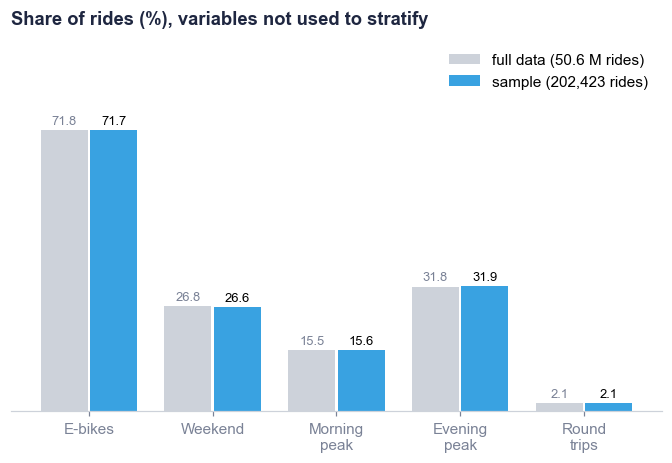

In [ ]:
# sample check: shares in the full data and in the stratified sample (from the cleaning notebook)
check = pd.read_csv(DATA + 'sample_check.csv', index_col=0)
check['key'] = check.index.astype(str)
keep = [('electric_bike', 'rideable_type', 'E-bikes'), ('True', 'is_weekend', 'Weekend'),
        ('morning', 'period', 'Morning\npeak'), ('evening', 'period', 'Evening\npeak'), ('True', 'round_trip', 'Round\ntrips')]
rows = [check[(check['key'] == k) & (check['variable'] == v)].iloc[0] for k, v, _ in keep]
pop = [r['population'] * 100 for r in rows]
smp = [r['sample'] * 100 for r in rows]

fig, ax = plt.subplots(figsize=(6.0, 4.1), layout='constrained')
xx = np.arange(len(keep))
b1 = ax.bar(xx - 0.2, pop, 0.38, color=LIGHT, label='full data (50.6 M rides)')
b2 = ax.bar(xx + 0.2, smp, 0.38, color=BLUE, label='sample (202,423 rides)')
ax.bar_label(b1, fmt='%.1f', fontsize=8.5, padding=2, color=GREY)
ax.bar_label(b2, fmt='%.1f', fontsize=8.5, padding=2)
ax.set_xticks(xx, [k[2] for k in keep])
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_ylim(0, 95)
ax.legend(loc='upper right')
ax.set_title('Share of rides (%), variables not used to stratify')
save(fig, 'data_sample')

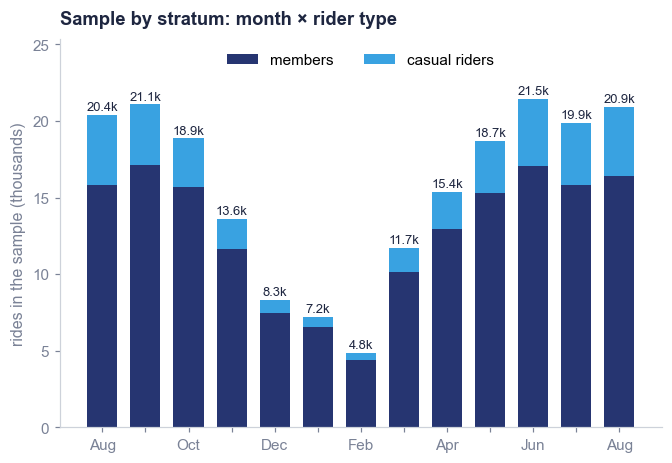

In [ ]:
# the sample by stratum: 13 months x 2 rider types, 0.4% of the rides of each stratum
strata = pd.crosstab(trips['month'], trips['member_casual'])
fig, ax = plt.subplots(figsize=(6.0, 4.1), layout='constrained')
xm = np.arange(len(strata))
ax.bar(xm, strata['member'] / 1000, color=NAVY, width=0.7, label='members')
ax.bar(xm, strata['casual'] / 1000, bottom=strata['member'] / 1000, color=BLUE, width=0.7, label='casual riders')
for i, (m, c) in enumerate(zip(strata['member'], strata['casual'])):
    ax.text(i, (m + c) / 1000 + 0.3, f'{(m + c) / 1000:.1f}k', ha='center', fontsize=8.5, color=INK)
ax.set_xticks(xm, [pd.Period(p).strftime('%b') if i % 2 == 0 else '' for i, p in enumerate(strata.index)])
ax.set_ylabel('rides in the sample (thousands)')
ax.legend(loc='upper center', ncol=2)
ax.set_ylim(0, (strata.sum(axis=1).max() / 1000) * 1.18)
ax.set_title('Sample by stratum: month × rider type')
save(fig, 'sample_strata')
numbers['strata_n'] = int(strata.size)
numbers['sample_max_month'] = [str(strata.sum(axis=1).idxmax()), int(strata.sum(axis=1).max())]
numbers['sample_min_month'] = [str(strata.sum(axis=1).idxmin()), int(strata.sum(axis=1).min())]
numbers['sample_casual'] = int(strata['casual'].sum())

## 3. Station segments: PCA, choice of k, profiles

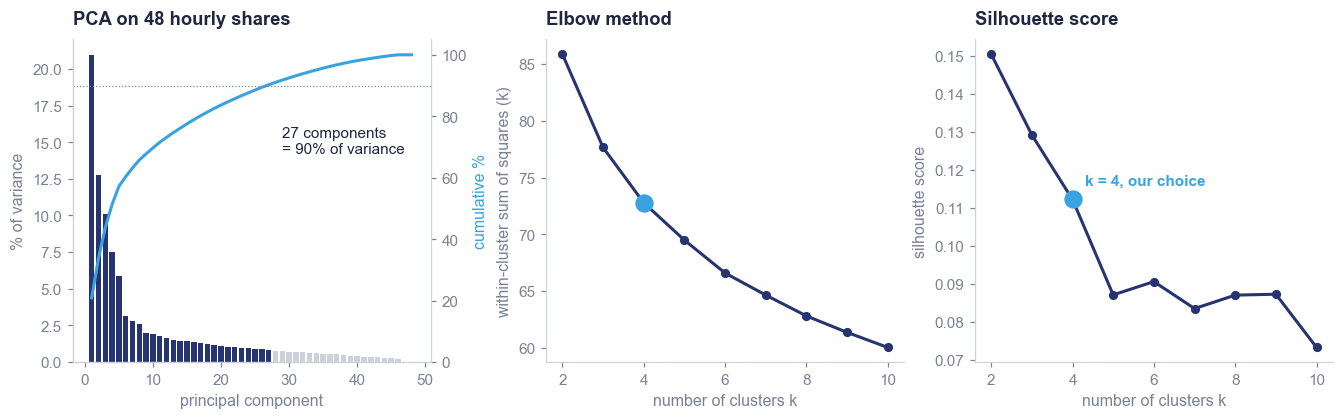

In [ ]:
inertia, silhouette = [], []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca)
    inertia.append(km.inertia_)
    silhouette.append(metrics.silhouette_score(X_pca, km.labels_))

full_pca = PCA(random_state=42).fit(X_scaled)
cumvar = full_pca.explained_variance_ratio_.cumsum() * 100

fig, axes = plt.subplots(1, 3, figsize=(12.1, 3.7), layout='constrained')
ax = axes[0]
ax.bar(range(1, 49), full_pca.explained_variance_ratio_ * 100, color=[NAVY if i < X_pca.shape[1] else LIGHT for i in range(48)], width=0.8)
ax2 = ax.twinx()
ax2.plot(range(1, 49), cumvar, color=BLUE, lw=2)
ax2.axhline(90, color=GREY, lw=0.8, ls=':')
ax2.text(29, 68, f'{X_pca.shape[1]} components\n= 90% of variance', fontsize=10, color=INK)
ax2.set_ylim(0, 105)
ax2.spines['right'].set_visible(True)
ax2.set_ylabel('cumulative %', color=BLUE)
ax.set_xlabel('principal component')
ax.set_ylabel('% of variance')
ax.set_title('PCA on 48 hourly shares')
ax = axes[1]
ax.plot(range(2, 11), np.array(inertia) / 1000, color=NAVY, lw=2, marker='o', ms=5)
ax.plot(4, inertia[2] / 1000, 'o', color=BLUE, ms=11)
ax.set_xlabel('number of clusters k')
ax.set_ylabel('within-cluster sum of squares (k)')
ax.set_title('Elbow method')
ax = axes[2]
ax.plot(range(2, 11), silhouette, color=NAVY, lw=2, marker='o', ms=5)
ax.plot(4, silhouette[2], 'o', color=BLUE, ms=11)
ax.text(4.3, silhouette[2] + 0.004, 'k = 4, our choice', fontsize=10, color=BLUE, fontweight='bold')
ax.set_xlabel('number of clusters k')
ax.set_ylabel('silhouette score')
ax.set_title('Silhouette score')
save(fig, 'seg_choice')
numbers['silhouette'] = [round(s, 3) for s in silhouette]

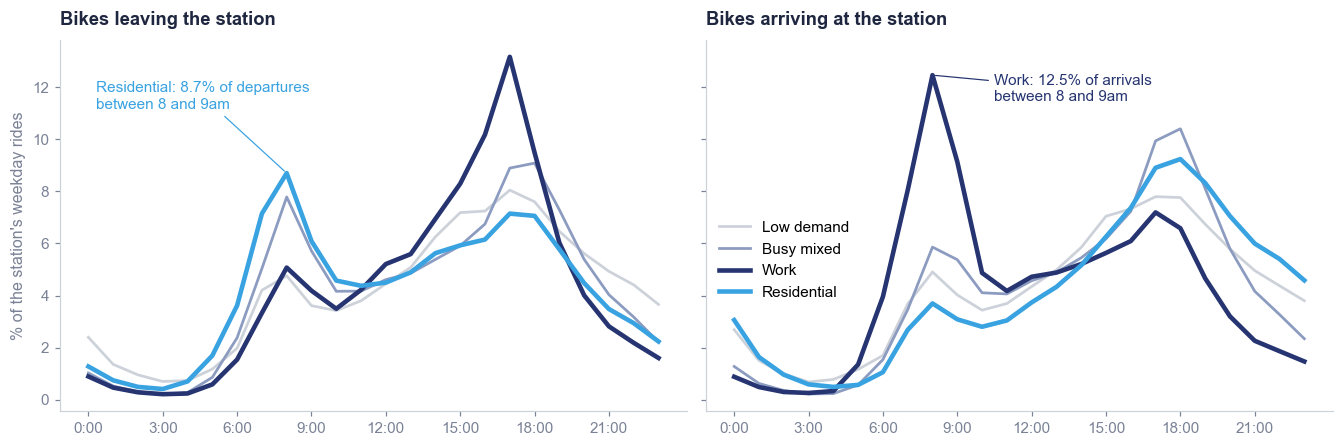

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.1, 3.95), layout='constrained', sharey=True)
for ax, cols, title in [(axes[0], dep_cols, 'Bikes leaving the station'), (axes[1], arr_cols, 'Bikes arriving at the station')]:
    for seg in ['Low demand', 'Busy mixed', 'Work', 'Residential']:
        prof = stations[stations['seg'] == seg][cols].mean().values * 100
        lw = 3 if seg in ['Residential', 'Work'] else 1.8
        ax.plot(range(24), prof, color=seg_colors[seg], lw=lw, label=seg)
    ax.set_xticks(hour_ticks, hour_labels)
    ax.set_title(title)
axes[0].set_ylabel('% of the station\'s weekday rides')
res = stations[stations['seg'] == 'Residential'][dep_cols].mean().values * 100
wrk = stations[stations['seg'] == 'Work'][arr_cols].mean().values * 100
axes[0].annotate(f'Residential: {res[8]:.1f}% of departures\nbetween 8 and 9am', (8, res[8]), (0.3, 11.2), fontsize=10, color=BLUE,
                 arrowprops=dict(arrowstyle='-', color=BLUE, lw=0.8))
axes[1].annotate(f'Work: {wrk[8]:.1f}% of arrivals\nbetween 8 and 9am', (8, wrk[8]), (10.5, 11.5), fontsize=10, color=NAVY,
                 arrowprops=dict(arrowstyle='-', color=NAVY, lw=0.8))
axes[1].legend(loc='upper left', ncol=1, bbox_to_anchor=(0.0, 0.55))
save(fig, 'seg_profiles')

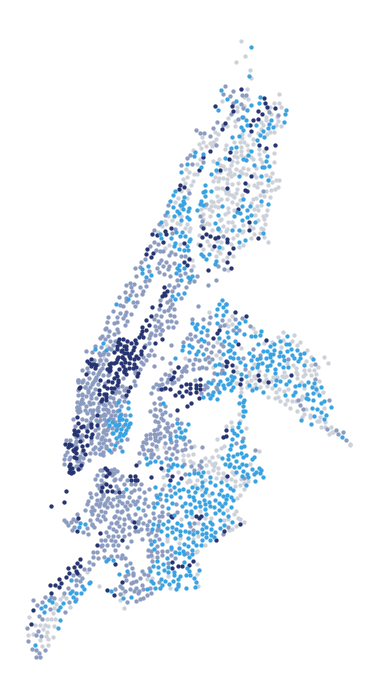

,stations,rides_per_day,capacity,casual,round_trip,net_flow
seg,,,,,,
Residential,628,26.14,24.47,0.21,0.04,-76.73
Work,337,78.96,43.03,0.20,0.03,-10.29
Busy mixed,842,90.95,36.95,0.18,0.03,78.56
Low demand,511,15.91,22.76,0.24,0.05,-39.09


In [ ]:
fig, ax = plt.subplots(figsize=(7, 8))
for seg in ['Low demand', 'Busy mixed', 'Work', 'Residential']:
    rows = stations[stations['seg'] == seg]
    ax.scatter(rows['lng'], rows['lat'], s=8, color=seg_colors[seg], linewidths=0)
ax.set_aspect(1.32)
ax.axis('off')
plt.savefig('charts/map_segments.png', dpi=250, transparent=True, bbox_inches='tight', pad_inches=0)
plt.show()

seg_table = stations.groupby('seg').agg(stations=('station_name', 'count'), rides_per_day=('departures', 'mean'), capacity=('capacity', 'mean'),
                                         casual=('casual_share', 'mean'), round_trip=('round_trip_share', 'mean'), net_flow=('net_flow', 'mean')).loc[seg_order]
seg_table['rides_per_day'] = seg_table['rides_per_day'] / 396
numbers['seg_table'] = seg_table.round(3).reset_index().values.tolist()
seg_table.round(2)

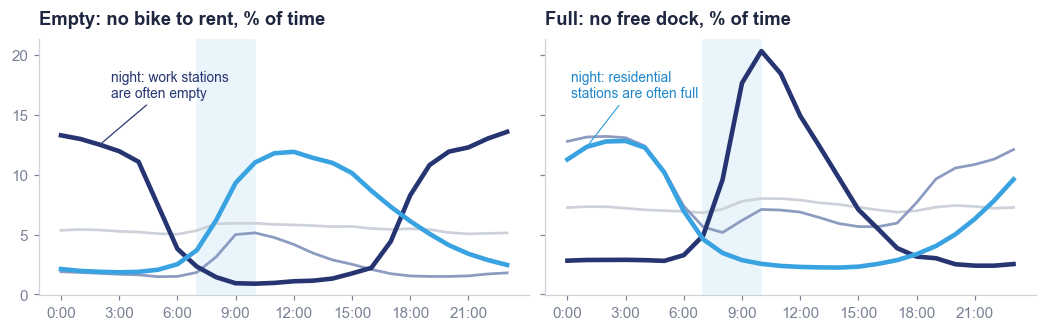

,pct_empty_morning,pct_full_morning
seg,,
Residential,6.4,3.5
Work,1.6,10.4
Busy mixed,3.3,5.5
Low demand,6.0,6.7


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(9.4, 2.9), layout='constrained', sharey=True)
for ax, prefix, title in [(axes[0], 'empty_', 'Empty: no bike to rent'), (axes[1], 'full_', 'Full: no free dock')]:
    ax.axvspan(7, 10, color=TINT)
    for seg in ['Low demand', 'Busy mixed', 'Work', 'Residential']:
        prof = stations[stations['seg'] == seg][[prefix + str(h) for h in range(24)]].mean().values
        lw = 3 if seg in ['Residential', 'Work'] else 1.8
        ax.plot(range(24), prof, color=seg_colors[seg], lw=lw, label=seg)
    ax.set_xticks(hour_ticks, hour_labels)
    ax.set_title(title + ', % of time')
w0 = stations[stations['seg'] == 'Work'][['empty_' + str(h) for h in range(24)]].mean().values
r0 = stations[stations['seg'] == 'Residential'][['full_' + str(h) for h in range(24)]].mean().values
axes[0].annotate('night: work stations\nare often empty', (2, w0[2]), (2.6, 16.5), fontsize=9, color=NAVY, arrowprops=dict(arrowstyle='-', color=NAVY, lw=0.8))
axes[1].annotate('night: residential\nstations are often full', (1, r0[1]), (0.2, 16.5), fontsize=9, color=BLUE_D, arrowprops=dict(arrowstyle='-', color=BLUE, lw=0.8))
save(fig, 'seg_hourly_state')

seg_morning = station_day[station_day['is_weekend'] == False].groupby('seg')[['pct_empty_morning', 'pct_full_morning']].mean().loc[seg_order].round(1)
numbers['seg_morning'] = seg_morning.reset_index().values.tolist()
seg_morning

## 4. Demand: weather and the regression

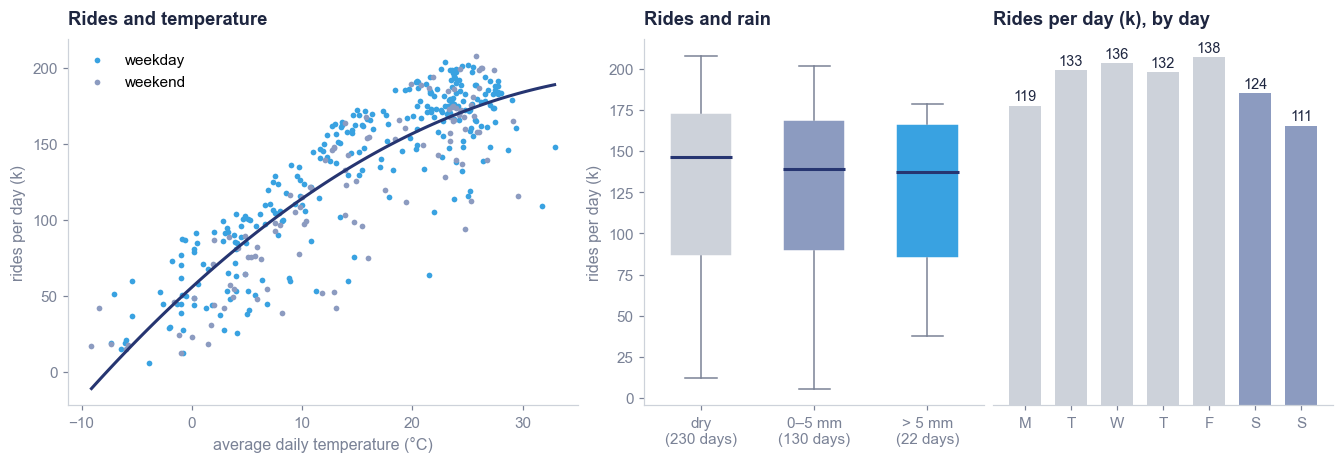

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12.1, 4.1), layout='constrained', width_ratios=[1.5, 1, 1])
d = daily.dropna()
ax = axes[0]
for we, c, lab in [(False, BLUE, 'weekday'), (True, MUTED, 'weekend')]:
    dd = d[d['is_weekend'] == we]
    ax.scatter(dd['tavg'], dd['rides'] / 1000, s=14, color=c, label=lab, linewidths=0)
coef = np.polyfit(d['tavg'], d['rides'] / 1000, 2)
xx = np.linspace(d['tavg'].min(), d['tavg'].max(), 100)
ax.plot(xx, np.polyval(coef, xx), color=NAVY, lw=2)
ax.set_xlabel('average daily temperature (°C)')
ax.set_ylabel('rides per day (k)')
ax.legend(loc='upper left')
ax.set_title('Rides and temperature')
ax = axes[1]
d = d.copy()
d['rain'] = pd.cut(d['prcp'], bins=[-1, 0, 5, 100], labels=['dry', '0–5 mm', '> 5 mm'])
groups = [d[d['rain'] == r]['rides'] / 1000 for r in ['dry', '0–5 mm', '> 5 mm']]
bp = ax.boxplot(groups, widths=0.55, patch_artist=True, showfliers=False, medianprops=dict(color=NAVY, lw=2))
for patch, c in zip(bp['boxes'], [LIGHT, MUTED, BLUE]):
    patch.set_facecolor(c)
    patch.set_edgecolor('white')
for el in ['whiskers', 'caps']:
    for l in bp[el]:
        l.set_color(GREY)
ax.set_xticks([1, 2, 3], [f'{r}\n({len(g)} days)' for r, g in zip(['dry', '0–5 mm', '> 5 mm'], groups)])
ax.set_ylabel('rides per day (k)')
ax.set_title('Rides and rain')
ax = axes[2]
wd = d.groupby(d.index.dayofweek)['rides'].mean() / 1000
ax.bar(range(7), wd.values, color=[LIGHT] * 5 + [MUTED] * 2, width=0.7)
for i, v in enumerate(wd.values):
    ax.text(i, v + 2, f'{v:.0f}', ha='center', fontsize=9.5, color=INK)
ax.set_xticks(range(7), ['M', 'T', 'W', 'T', 'F', 'S', 'S'])
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_title('Rides per day (k), by day')
save(fig, 'demand_weather')
numbers['rides_by_rain'] = [round(g.median(), 1) for g in groups]

In [ ]:
last_week = station_day[['station_name', 'date', 'departures']].copy()
last_week['date'] = last_week['date'] + pd.Timedelta(days=7)
last_week.columns = ['station_name', 'date', 'departures_last_week']
station_day = station_day.merge(last_week, on=['station_name', 'date'], how='left')

reg = station_day.dropna(subset=['departures_last_week', 'tavg', 'prcp']).sample(100000, random_state=42)
reg['log_departures'] = np.log1p(reg['departures'])
reg['log_departures_last_week'] = np.log1p(reg['departures_last_week'])
X_reg = pd.get_dummies(reg[['weekday', 'month', 'holiday', 'tavg', 'prcp', 'wspd', 'capacity', 'segment', 'log_departures_last_week']],
                       columns=['weekday', 'month', 'segment'], drop_first=True, dtype='int')
Y_reg = reg['log_departures']
Xtrain, Xtest, Ytrain, Ytest = train_test_split(X_reg, Y_reg, test_size=0.2, random_state=42)
model = LinearRegression().fit(Xtrain, Ytrain)
Ypred = model.predict(Xtest)
print('out-of-sample R2:', model.score(Xtest, Ytest))

time_cols = [c for c in X_reg.columns if c.startswith('weekday') or c.startswith('month') or c == 'holiday']
weather_cols = ['tavg', 'prcp', 'wspd']
station_cols = ['capacity'] + [c for c in X_reg.columns if c.startswith('segment')]
r2 = {}
for name, cols in [('Calendar', time_cols), ('Weather', weather_cols), ('Calendar + weather', time_cols + weather_cols),
                   ('Station', station_cols), ('Station + last week', station_cols + ['log_departures_last_week']), ('All variables', list(X_reg.columns))]:
    r2[name] = LinearRegression().fit(Xtrain[cols], Ytrain).score(Xtest[cols], Ytest)
r2

out-of-sample R2: 0.8492104786899892


{'Calendar': 0.11570533562591823,
 'Weather': 0.11481414622023012,
 'Calendar + weather': 0.12809595033726784,
 'Station': 0.4404071385055448,
 'Station + last week': 0.8294525195898357,
 'All variables': 0.8492104786899892}

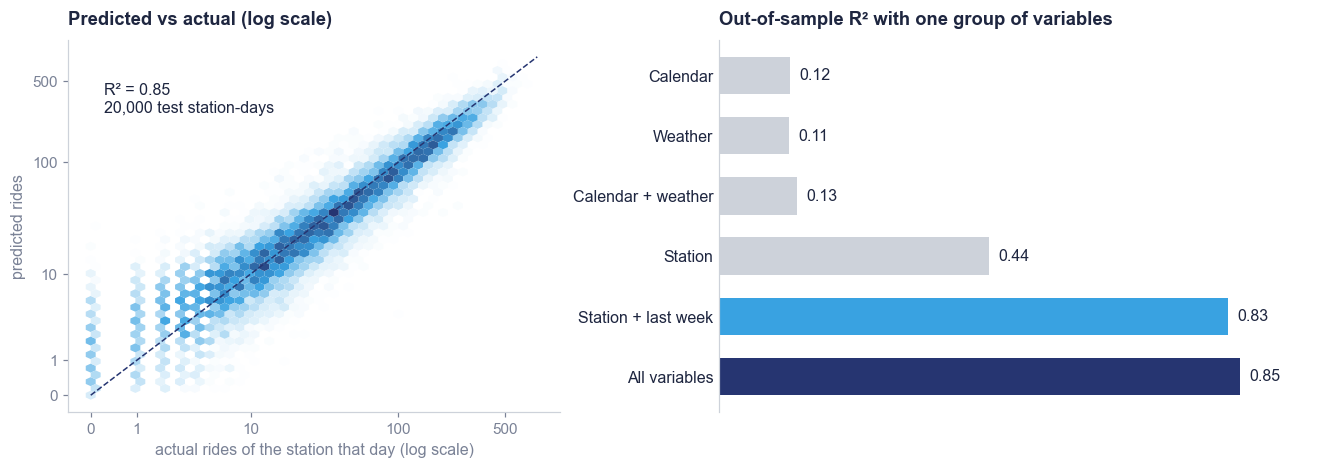

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.1, 4.15), layout='constrained', width_ratios=[1, 1.25])
ax = axes[0]
ax.hexbin(Ytest, Ypred, gridsize=45, cmap=blues, mincnt=1, linewidths=0, extent=(0, 6.7, 0, 6.7))
ax.plot([0, 6.7], [0, 6.7], color=NAVY, lw=1, ls='--')
ticks = [0, 1, 10, 100, 500]
ax.set_xticks(np.log1p(ticks), ticks)
ax.set_yticks(np.log1p(ticks), ticks)
ax.set_xlabel('actual rides of the station that day (log scale)')
ax.set_ylabel('predicted rides')
ax.text(0.2, 5.6, f'R² = {model.score(Xtest, Ytest):.2f}\n20,000 test station-days', fontsize=10.5, color=INK)
ax.set_title('Predicted vs actual (log scale)')
ax = axes[1]
names = list(r2.keys())[::-1]
vals = [r2[n] for n in names]
cols = [NAVY if n == 'All variables' else BLUE if n == 'Station + last week' else LIGHT for n in names]
ax.barh(names, vals, color=cols, height=0.62)
for i, v in enumerate(vals):
    ax.text(v + 0.015, i, f'{v:.2f}', va='center', fontsize=10.5, color=INK)
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.spines['bottom'].set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=10.5, labelcolor=INK)
ax.set_title('Out-of-sample R² with one group of variables')
save(fig, 'demand_fit')
numbers['r2_groups'] = {k: round(v, 3) for k, v in r2.items()}

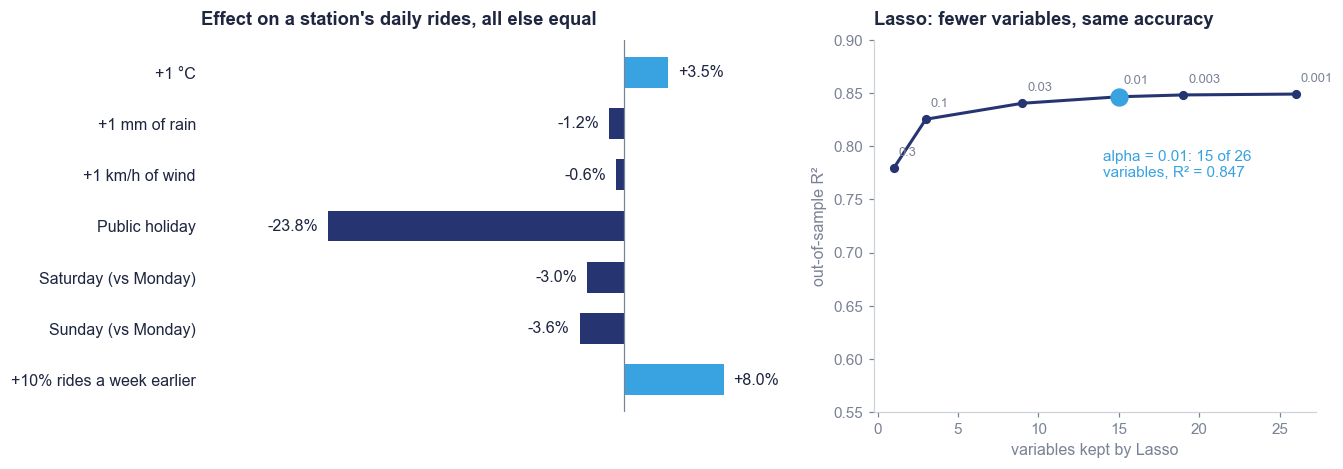

{'+1 °C': 3.5, '+1 mm of rain': -1.2, '+1 km/h of wind': -0.6, 'Public holiday': -23.8, 'Saturday (vs Monday)': -3.0, 'Sunday (vs Monday)': -3.6, '+10% rides a week earlier': 8.0} [[0.001, 26.0, 0.849], [0.003, 19.0, 0.848], [0.01, 15.0, 0.847], [0.03, 9.0, 0.84], [0.1, 3.0, 0.825], [0.3, 1.0, 0.779]]


In [ ]:
# coefficients as % effects, and Lasso: fewer variables, same accuracy
coefs = pd.Series(model.coef_, index=X_reg.columns)
effects = pd.Series({'+1 °C': coefs['tavg'], '+1 mm of rain': coefs['prcp'], '+1 km/h of wind': coefs['wspd'],
                     'Public holiday': coefs['holiday'], 'Saturday (vs Monday)': coefs['weekday_5'], 'Sunday (vs Monday)': coefs['weekday_6'],
                     '+10% rides a week earlier': coefs['log_departures_last_week'] * np.log(1.1)})
effects = (np.exp(effects) - 1) * 100

scaler = StandardScaler().fit(Xtrain)
Xtrain_s, Xtest_s = scaler.transform(Xtrain), scaler.transform(Xtest)
lasso_path = []
for a in [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]:
    las = Lasso(alpha=a, random_state=42).fit(Xtrain_s, Ytrain)
    lasso_path.append([a, int((las.coef_ != 0).sum()), las.score(Xtest_s, Ytest)])
lasso_path = pd.DataFrame(lasso_path, columns=['alpha', 'variables', 'r2'])

fig, axes = plt.subplots(1, 2, figsize=(12.1, 4.15), layout='constrained', width_ratios=[1.35, 1])
ax = axes[0]
e = effects[::-1]
ax.barh(e.index, e.values, color=[BLUE if v > 0 else NAVY for v in e.values], height=0.6)
for i, v in enumerate(e.values):
    ax.text(v + (0.8 if v >= 0 else -0.8), i, f'{v:+.1f}%', va='center', ha='left' if v >= 0 else 'right', fontsize=10.5, color=INK)
ax.axvline(0, color=GREY, lw=0.8)
ax.set_xlim(-34, 14)
ax.set_xticks([])
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.tick_params(axis='y', length=0, labelsize=10.5, labelcolor=INK)
ax.set_title('Effect on a station\'s daily rides, all else equal')
ax = axes[1]
ax.plot(lasso_path['variables'], lasso_path['r2'], color=NAVY, lw=2, marker='o', ms=5)
p = lasso_path[lasso_path['alpha'] == 0.01].iloc[0]
ax.plot(p['variables'], p['r2'], 'o', color=BLUE, ms=11)
ax.text(p['variables'] - 1, p['r2'] - 0.075, f"alpha = 0.01: {int(p['variables'])} of 26\nvariables, R² = {p['r2']:.3f}", fontsize=10, color=BLUE)
for _, r in lasso_path.iterrows():
    ax.text(r['variables'] + 0.3, r['r2'] + 0.012, f"{r['alpha']:g}", ha='left', fontsize=8.5, color=GREY)
ax.set_xlabel('variables kept by Lasso')
ax.set_ylabel('out-of-sample R²')
ax.set_ylim(0.55, 0.9)
ax.set_title('Lasso: fewer variables, same accuracy')
save(fig, 'demand_coef')
numbers['effects'] = effects.round(1).to_dict()
numbers['lasso_path'] = lasso_path.round(3).values.tolist()
print(numbers['effects'], numbers['lasso_path'])

## 5. Members vs casual riders

In [ ]:
trips = trips.merge(stations[['station_name', 'segment']], left_on='start_station_name', right_on='station_name', how='left')
trips = trips.dropna(subset=['segment', 'tavg', 'prcp'])
Y = (trips['member_casual'] == 'casual').astype(int)
feature_cols = trips[['duration_min', 'distance_km', 'hour', 'is_weekend', 'holiday', 'round_trip', 'rideable_type', 'tavg', 'prcp', 'segment']]
X = pd.get_dummies(feature_cols, columns=['rideable_type', 'segment'], dtype='int')
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

log_clf = LogisticRegression(max_iter=1000).fit(X_train, y_train)
gnb = GaussianNB().fit(X_train, y_train)
tree_clf = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_train, y_train)
rf_classifier = RandomForestClassifier(n_estimators=100, min_samples_leaf=20, random_state=42).fit(X_train, y_train)
rider_models = {'Naive Bayes': gnb, 'Decision tree': tree_clf, 'Logistic regression': log_clf, 'Random forest': rf_classifier}

In [ ]:
# KNN: validation curve over k (same as the analysis notebook, section 5.4)
scaler_knn = StandardScaler().fit(X_train)
X_train_knn = scaler_knn.transform(X_train)[:20000]
y_train_knn = y_train.iloc[:20000]
X_test_knn = scaler_knn.transform(X_test)
k_values = [1, 3, 5, 11, 25, 51, 101, 201, 501, 1001]
train_auc, test_auc = [], []
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train_knn, y_train_knn)
    train_auc.append(metrics.roc_auc_score(y_train_knn, knn.predict_proba(X_train_knn)[:, 1]))
    test_auc.append(metrics.roc_auc_score(y_test, knn.predict_proba(X_test_knn)[:, 1]))
best_k = k_values[int(np.argmax(test_auc))]
knn_best = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_knn, y_train_knn)
numbers['knn'] = {'k': k_values, 'train': [round(v, 3) for v in train_auc], 'test': [round(v, 3) for v in test_auc], 'best_k': best_k}
numbers['knn']

{'k': [1, 3, 5, 11, 25, 51, 101, 201, 501, 1001],
 'train': [np.float64(1.0),
  np.float64(0.901),
  np.float64(0.85),
  np.float64(0.785),
  np.float64(0.741),
  np.float64(0.716),
  np.float64(0.698),
  np.float64(0.684),
  np.float64(0.668),
  np.float64(0.661)],
 'test': [np.float64(0.547),
  np.float64(0.595),
  np.float64(0.614),
  np.float64(0.645),
  np.float64(0.668),
  np.float64(0.68),
  np.float64(0.68),
  np.float64(0.677),
  np.float64(0.666),
  np.float64(0.663)],
 'best_k': 101}

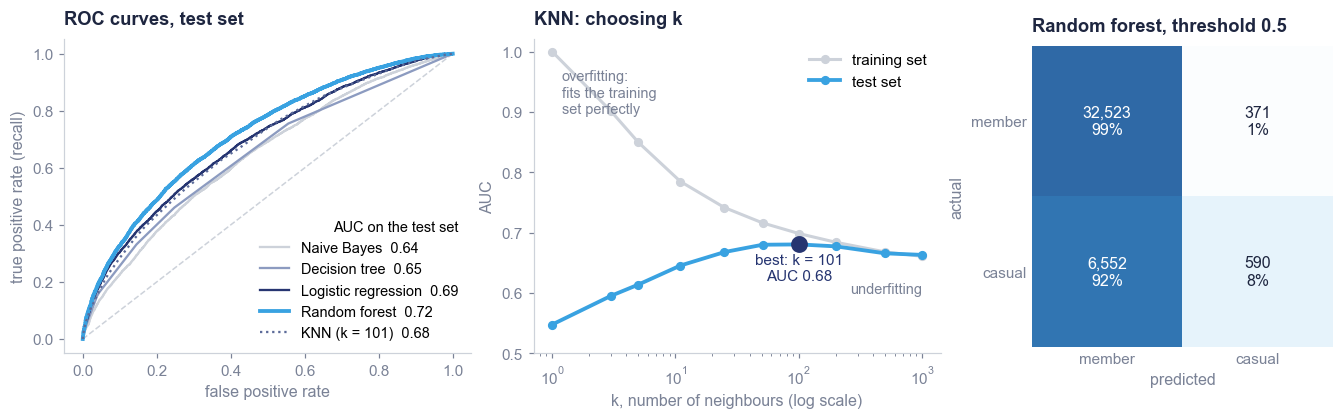

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12.1, 3.7), layout='constrained', width_ratios=[1.15, 1.15, 0.85])
ax = axes[0]
ax.plot([0, 1], [0, 1], color=LIGHT, ls='--', lw=1)
curves = dict(rider_models)
curves[f'KNN (k = {best_k})'] = knn_best
for name, clf in curves.items():
    Xt = X_test_knn if name.startswith('KNN') else X_test
    fpr, tpr, _ = roc_curve(y_test, clf.predict_proba(Xt)[:, 1])
    c = {'Random forest': BLUE, 'Logistic regression': NAVY, 'Decision tree': MUTED, 'Naive Bayes': LIGHT}.get(name, '#5C6B99')
    ax.plot(fpr, tpr, color=c, lw=2.5 if name == 'Random forest' else 1.5, ls=':' if name.startswith('KNN') else '-', label=f'{name}  {auc(fpr, tpr):.2f}')
ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate (recall)')
ax.legend(loc='lower right', title='AUC on the test set', title_fontsize=9.5, alignment='right', fontsize=9.5)
ax.set_title('ROC curves, test set')
ax = axes[1]
ax.plot(k_values, train_auc, color=LIGHT, lw=2, marker='o', ms=5, label='training set')
ax.plot(k_values, test_auc, color=BLUE, lw=2.5, marker='o', ms=5, label='test set')
ax.plot(best_k, max(test_auc), 'o', color=NAVY, ms=10)
ax.text(best_k, max(test_auc) - 0.06, f'best: k = {best_k}\nAUC {max(test_auc):.2f}', ha='center', fontsize=10, color=NAVY)
ax.text(1.2, 0.97, 'overfitting:\nfits the training\nset perfectly', fontsize=9.5, color=GREY, va='top')
ax.text(1000, 0.60, 'underfitting', fontsize=9.5, color=GREY, ha='right')
ax.set_xscale('log')
ax.set_xlabel('k, number of neighbours (log scale)')
ax.set_ylabel('AUC')
ax.set_ylim(0.5, 1.02)
ax.legend(loc='upper right')
ax.set_title('KNN: choosing k')
ax = axes[2]
cm = confusion_matrix(y_test, rf_classifier.predict(X_test))
ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap=blues, vmin=0, vmax=1.3)
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum() * 100
        ax.text(j, i, f'{cm[i, j]:,}\n{share:.0f}%', ha='center', va='center', fontsize=10.5, color='white' if share > 60 else INK)
ax.set_xticks([0, 1], ['member', 'casual'])
ax.set_yticks([0, 1], ['member', 'casual'])
ax.set_xlabel('predicted')
ax.set_ylabel('actual')
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title('Random forest, threshold 0.5')
save(fig, 'riders_main')

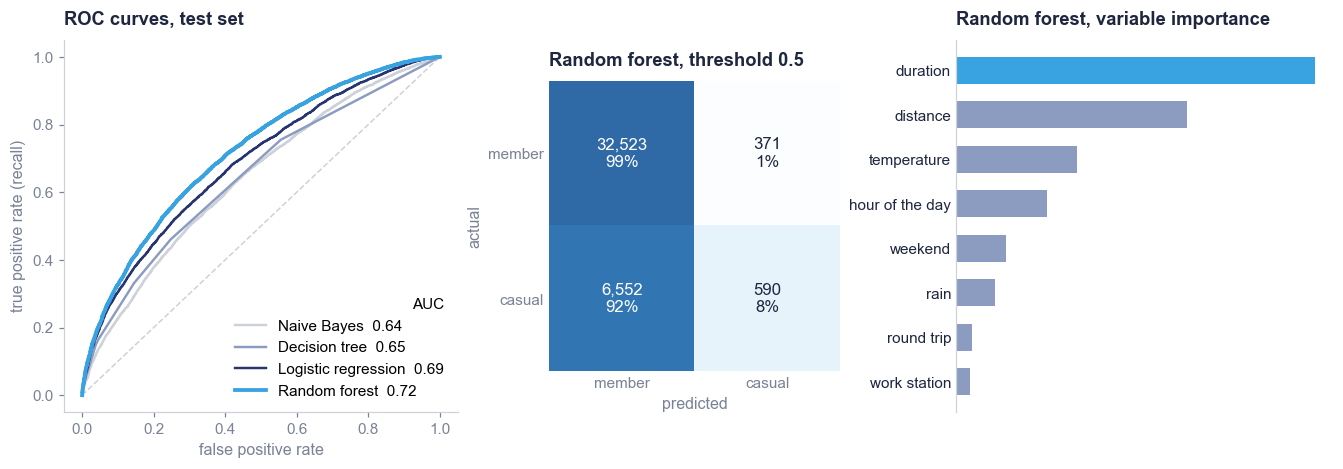

In [ ]:
nice = {'duration_min': 'duration', 'distance_km': 'distance', 'hour': 'hour of the day', 'is_weekend': 'weekend', 'holiday': 'holiday',
        'round_trip': 'round trip', 'tavg': 'temperature', 'prcp': 'rain', 'rideable_type_classic_bike': 'classic bike',
        'rideable_type_electric_bike': 'e-bike', 'segment_Busy mixed': 'busy mixed station', 'segment_Low demand / leisure': 'low-demand station',
        'segment_Residential (morning departures)': 'residential station', 'segment_Work (morning arrivals)': 'work station'}

fig, axes = plt.subplots(1, 3, figsize=(12.1, 4.15), layout='constrained', width_ratios=[1.15, 0.85, 1.1])
ax = axes[0]
ax.plot([0, 1], [0, 1], color=LIGHT, ls='--', lw=1)
for name, clf in rider_models.items():
    fpr, tpr, _ = roc_curve(y_test, clf.predict_proba(X_test)[:, 1])
    c = {'Random forest': BLUE, 'Logistic regression': NAVY, 'Decision tree': MUTED, 'Naive Bayes': LIGHT}[name]
    ax.plot(fpr, tpr, color=c, lw=2.5 if name == 'Random forest' else 1.6, label=f'{name}  {auc(fpr, tpr):.2f}')
ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate (recall)')
ax.legend(loc='lower right', title='AUC', title_fontsize=10, alignment='right')
ax.set_title('ROC curves, test set')
ax = axes[1]
cm = confusion_matrix(y_test, rf_classifier.predict(X_test))
ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap=blues, vmin=0, vmax=1.3)
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum() * 100
        ax.text(j, i, f'{cm[i, j]:,}\n{share:.0f}%', ha='center', va='center', fontsize=11, color='white' if share > 60 else INK)
ax.set_xticks([0, 1], ['member', 'casual'])
ax.set_yticks([0, 1], ['member', 'casual'])
ax.set_xlabel('predicted')
ax.set_ylabel('actual')
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title('Random forest, threshold 0.5')
ax = axes[2]
imp = pd.Series(rf_classifier.feature_importances_, index=[nice[c] for c in X.columns]).sort_values().tail(8)
ax.barh(imp.index, imp.values, color=[BLUE if v == imp.max() else MUTED for v in imp.values], height=0.6)
ax.set_xticks([])
ax.spines['bottom'].set_visible(False)
ax.tick_params(axis='y', length=0, labelcolor=INK)
ax.set_title('Random forest, variable importance')
save(fig, 'riders_models')
numbers['rider_cm'] = cm.tolist()

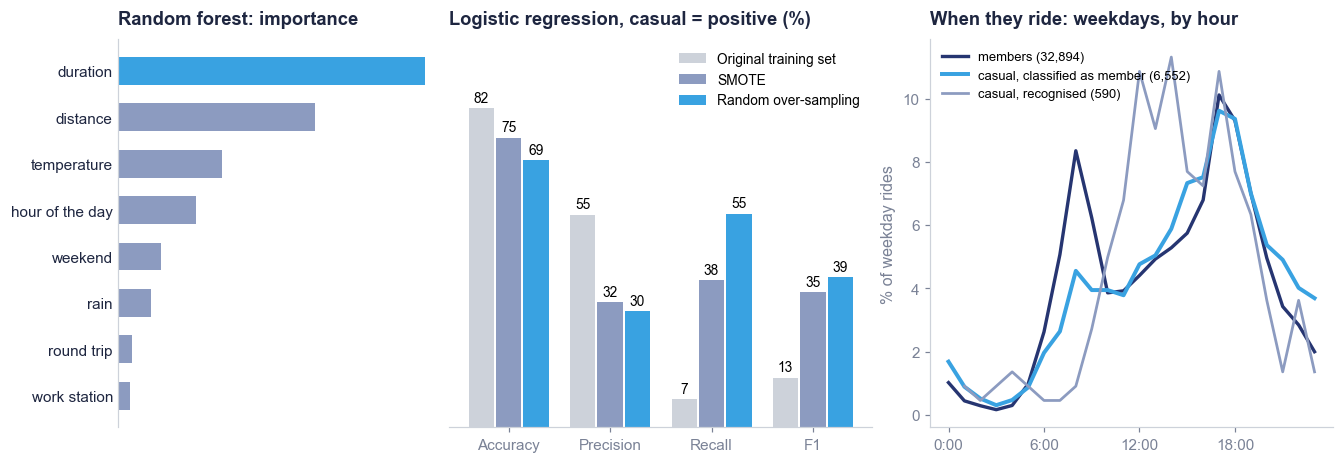

{'n': 6552, 'casual': 7142, 'median_min': 11.7, 'weekday': np.float64(65.4), 'ebike': np.float64(76.1), 'median_km': 1.71} [['Original\ntraining set', 82.4, 54.9, 7.3, 12.8], ['SMOTE', 74.7, 32.3, 38.0, 34.9], ['Random\nover-sampling', 69.0, 29.9, 55.1, 38.8]]


In [ ]:
X_train_smote, y_train_smote = SMOTE(random_state=42).fit_resample(X_train, y_train)
X_train_over, y_train_over = RandomOverSampler(random_state=42).fit_resample(X_train, y_train)
res = []
for name, Xr, yr in [('Original\ntraining set', X_train, y_train), ('SMOTE', X_train_smote, y_train_smote), ('Random\nover-sampling', X_train_over, y_train_over)]:
    pred = LogisticRegression(max_iter=1000).fit(Xr, yr).predict(X_test)
    res.append([name, metrics.accuracy_score(y_test, pred), metrics.precision_score(y_test, pred), metrics.recall_score(y_test, pred), metrics.f1_score(y_test, pred)])
res = pd.DataFrame(res, columns=['set', 'Accuracy', 'Precision', 'Recall', 'F1']).set_index('set')

test = trips.loc[X_test.index].copy()
test['proba_casual'] = rf_classifier.predict_proba(X_test)[:, 1]
test['group'] = np.where(test['member_casual'] == 'member', 'members',
                np.where(test['proba_casual'] < 0.5, 'casual, classified as member', 'casual, recognised'))

fig, axes = plt.subplots(1, 3, figsize=(12.1, 4.1), layout='constrained', width_ratios=[0.8, 1.05, 1])
ax = axes[0]
imp = pd.Series(rf_classifier.feature_importances_, index=[nice[c] for c in X.columns]).sort_values().tail(8)
ax.barh(imp.index, imp.values, color=[BLUE if v == imp.max() else MUTED for v in imp.values], height=0.6)
ax.set_xticks([])
ax.spines['bottom'].set_visible(False)
ax.tick_params(axis='y', length=0, labelcolor=INK)
ax.set_title('Random forest: importance')
ax = axes[1]
xx = np.arange(4)
for k, (s, c) in enumerate(zip(res.index, [LIGHT, MUTED, BLUE])):
    b = ax.bar(xx + (k - 1) * 0.27, res.loc[s].values * 100, 0.25, color=c, label=s.replace('\n', ' '))
    ax.bar_label(b, fmt='%.0f', fontsize=9, padding=2)
ax.set_xticks(xx, res.columns)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_ylim(0, 100)
ax.legend(loc='upper right', ncol=1, fontsize=9)
ax.set_title('Logistic regression, casual = positive (%)')
ax = axes[2]
for g, c, lw in [('members', NAVY, 2.2), ('casual, classified as member', BLUE, 2.6), ('casual, recognised', MUTED, 1.8)]:
    sh = test[(test['group'] == g) & (test['is_weekend'] == False)]['hour'].value_counts(normalize=True).sort_index() * 100
    ax.plot(sh.index, sh.values, color=c, lw=lw, label=f"{g} ({(test['group'] == g).sum():,})")
ax.set_xticks(range(0, 24, 6), [f'{h}:00' for h in range(0, 24, 6)])
ax.set_ylabel('% of weekday rides')
ax.legend(loc='upper left', fontsize=8.5)
ax.set_title('When they ride: weekdays, by hour')
save(fig, 'riders_balance')

look = test[test['group'] == 'casual, classified as member']
numbers['lookalike'] = {'n': len(look), 'casual': int((test['member_casual'] == 'casual').sum()), 'median_min': round(look['duration_min'].median(), 1),
                        'weekday': round((look['is_weekend'] == False).mean() * 100, 1), 'ebike': round((look['rideable_type'] == 'electric_bike').mean() * 100, 1),
                        'median_km': round(look['distance_km'].median(), 2)}
numbers['balance'] = (res * 100).round(1).reset_index().values.tolist()
trips['commute_peak'] = (trips['is_weekend'] == False) & trips['period'].isin(['morning', 'evening'])
numbers['commute_peak'] = (trips.groupby('member_casual')['commute_peak'].mean() * 100).round(1).to_dict()
print(numbers['lookalike'], numbers['balance'])

## 6. Empty tomorrow: target, models, drivers, truck list

In [ ]:
tomorrow = station_day[['station_name', 'date', 'pct_empty_morning', 'weekday', 'is_weekend', 'holiday', 'tavg', 'prcp']].copy()
tomorrow['date'] = tomorrow['date'] - pd.Timedelta(days=1)
tomorrow.columns = ['station_name', 'date', 'tomorrow_pct_empty_morning', 'tomorrow_weekday', 'tomorrow_is_weekend', 'tomorrow_holiday', 'tomorrow_tavg', 'tomorrow_prcp']
data = station_day.merge(tomorrow, on=['station_name', 'date'])
data['empty_tomorrow'] = (data['tomorrow_pct_empty_morning'] >= 33).astype(int)
data['net_flow_morning'] = data['arr_morning'] - data['dep_morning']
data = data.dropna(subset=['tomorrow_tavg', 'tomorrow_prcp'])
print('share empty tomorrow:', data['empty_tomorrow'].mean())

features_e = ['pct_empty_morning', 'pct_full_morning', 'pct_empty_evening', 'pct_full_evening', 'departures', 'arrivals', 'net_flow_morning',
              'capacity', 'segment', 'tomorrow_weekday', 'tomorrow_is_weekend', 'tomorrow_holiday', 'tomorrow_tavg', 'tomorrow_prcp']
sample_e = data.sample(150000, random_state=42)
X_e = pd.get_dummies(sample_e[features_e], columns=['segment'], dtype='int')
y_e = sample_e['empty_tomorrow']
X_train_e, X_test_e, y_train_e, y_test_e = train_test_split(X_e, y_e, test_size=0.2, random_state=42)

share empty tomorrow: 0.04671918922471543


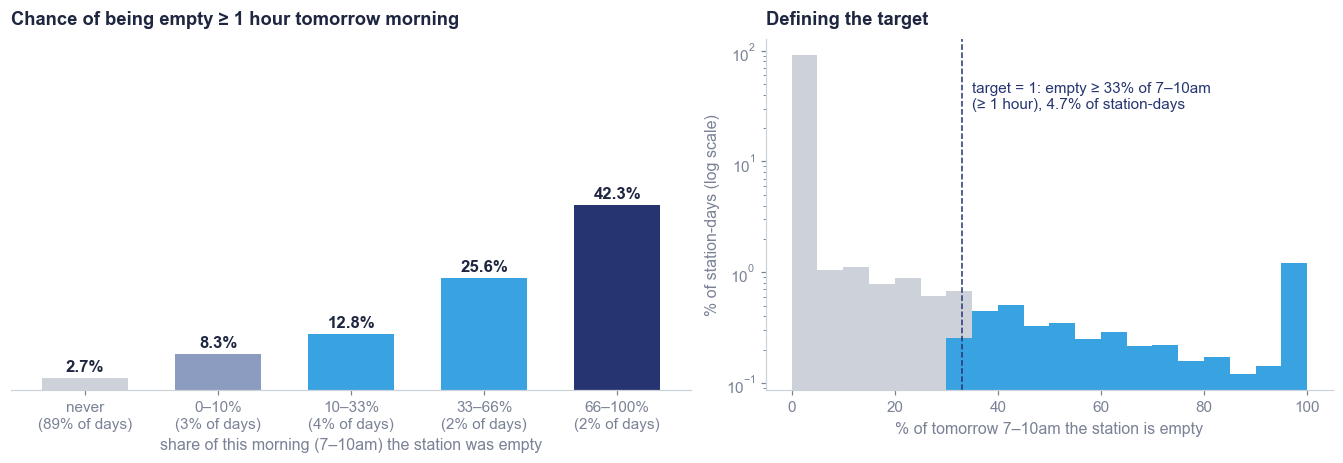

{'never': 2.7, '0–10%': 8.3, '10–33%': 12.8, '33–66%': 25.6, '66–100%': 42.3} {'never': 89.0, '0–10%': 2.7, '10–33%': 3.6, '33–66%': 2.5, '66–100%': 2.2}


In [ ]:
# persistence: chance of being empty tomorrow given how long the station was empty this morning
bins = [-1, 0, 10, 33, 66, 100]
labels = ['never', '0–10%', '10–33%', '33–66%', '66–100%']
data['today_bin'] = pd.cut(data['pct_empty_morning'], bins=bins, labels=labels)
persist = data.groupby('today_bin', observed=True)['empty_tomorrow'].agg(['mean', 'size'])

fig, axes = plt.subplots(1, 2, figsize=(12.1, 4.1), layout='constrained', width_ratios=[1.2, 1])
ax = axes[0]
ax.bar(range(5), persist['mean'] * 100, color=[LIGHT, MUTED, BLUE, BLUE, NAVY], width=0.65)
for i, (m, n) in enumerate(zip(persist['mean'], persist['size'])):
    ax.text(i, m * 100 + 1.5, f'{m * 100:.1f}%', ha='center', fontsize=11, color=INK, fontweight='bold')
ax.set_xticks(range(5), [f'{l}\n({n / len(data) * 100:.0f}% of days)' for l, n in zip(labels, persist['size'])])
ax.set_xlabel('share of this morning (7–10am) the station was empty')
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_ylim(0, 80)
ax.set_title('Chance of being empty ≥ 1 hour tomorrow morning')
ax = axes[1]
ax.hist(data['tomorrow_pct_empty_morning'], bins=np.arange(0, 101, 5), color=LIGHT, weights=np.ones(len(data)) / len(data) * 100)
ax.hist(data[data['tomorrow_pct_empty_morning'] >= 33]['tomorrow_pct_empty_morning'], bins=np.arange(0, 101, 5), color=BLUE,
        weights=np.ones((data['tomorrow_pct_empty_morning'] >= 33).sum()) / len(data) * 100)
ax.set_yscale('log')
ax.axvline(33, color=NAVY, lw=1, ls='--')
ax.text(35, 30, f"target = 1: empty ≥ 33% of 7–10am\n(≥ 1 hour), {data['empty_tomorrow'].mean() * 100:.1f}% of station-days", fontsize=10, color=NAVY)
ax.set_xlabel('% of tomorrow 7–10am the station is empty')
ax.set_ylabel('% of station-days (log scale)')
ax.set_title('Defining the target')
save(fig, 'pred_target')
numbers['persist'] = (persist['mean'] * 100).round(1).to_dict()
numbers['persist_n'] = (persist['size'] / len(data) * 100).round(1).to_dict()
print(numbers['persist'], numbers['persist_n'])

In [ ]:
candidates = {'Decision tree': DecisionTreeClassifier(max_depth=5, random_state=42),
              'Logistic regression': LogisticRegression(max_iter=1000),
              'Random forest': RandomForestClassifier(n_estimators=100, min_samples_leaf=20, random_state=42),
              'XGBoost': xgb.XGBClassifier(max_depth=4, learning_rate=0.3, n_estimators=100, random_state=42)}
test_curves = {}
for name, m in candidates.items():
    m.fit(X_train_e, y_train_e)
    proba = m.predict_proba(X_test_e)[:, 1]
    fpr, tpr, _ = roc_curve(y_test_e, proba)
    test_curves[name] = (fpr, tpr, auc(fpr, tpr))
{k: round(v[2], 4) for k, v in test_curves.items()}

{'Decision tree': np.float64(0.842),
 'Logistic regression': np.float64(0.8652),
 'Random forest': np.float64(0.8927),
 'XGBoost': np.float64(0.9064)}

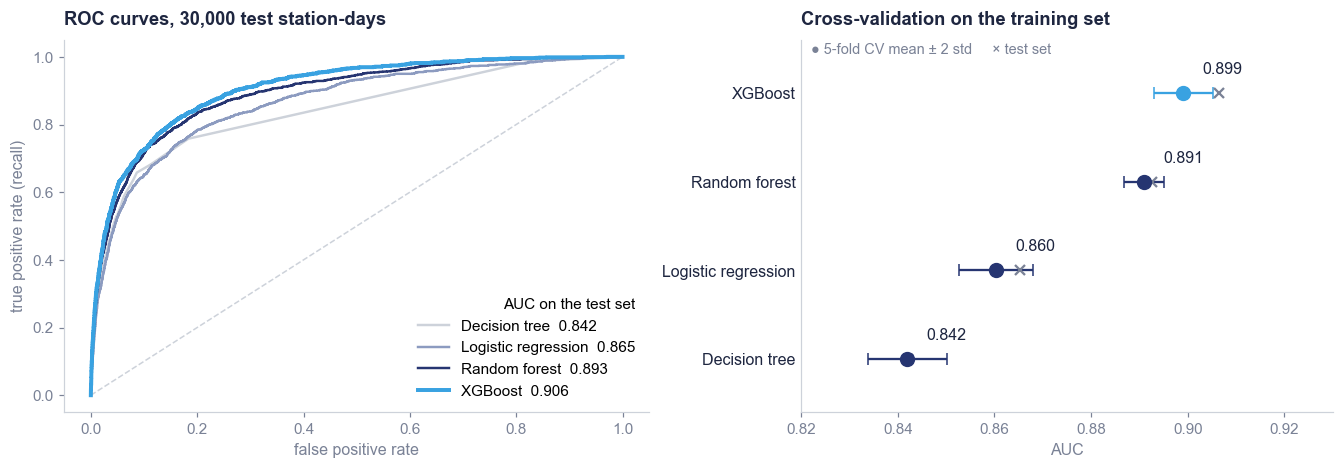

In [ ]:
# cross-validated AUC from the analysis notebook (section 6.2, 5-fold CV on the training set)
cv = pd.DataFrame({'mean': [0.8420, 0.8603, 0.8909, 0.8991], 'std': [0.0041, 0.0038, 0.0021, 0.0031]},
                  index=['Decision tree', 'Logistic regression', 'Random forest', 'XGBoost'])

fig, axes = plt.subplots(1, 2, figsize=(12.1, 4.15), layout='constrained', width_ratios=[1.1, 1])
ax = axes[0]
ax.plot([0, 1], [0, 1], color=LIGHT, ls='--', lw=1)
for name, (fpr, tpr, a) in test_curves.items():
    c = {'XGBoost': BLUE, 'Random forest': NAVY, 'Logistic regression': MUTED, 'Decision tree': LIGHT}[name]
    ax.plot(fpr, tpr, color=c, lw=2.6 if name == 'XGBoost' else 1.6, label=f'{name}  {a:.3f}')
ax.legend(loc='lower right', title='AUC on the test set', title_fontsize=10, alignment='right')
ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate (recall)')
ax.set_title('ROC curves, 30,000 test station-days')
ax = axes[1]
for i, (name, r) in enumerate(cv.iterrows()):
    c = BLUE if name == 'XGBoost' else NAVY
    ax.errorbar(r['mean'], i, xerr=r['std'] * 2, fmt='o', color=c, ms=9, capsize=4, lw=1.5)
    ax.text(r['mean'] + 0.004, i + 0.22, f"{r['mean']:.3f}", fontsize=10.5, color=INK)
    ax.plot(test_curves[name][2], i, 'x', color=GREY, ms=7, mew=1.5)
ax.set_yticks(range(4), cv.index)
ax.tick_params(axis='y', length=0, labelcolor=INK, labelsize=10.5)
ax.set_xlim(0.82, 0.93)
ax.set_ylim(-0.6, 3.6)
ax.set_xlabel('AUC')
ax.text(0.822, 3.45, '● 5-fold CV mean ± 2 std     × test set', fontsize=9.5, color=GREY)
ax.set_title('Cross-validation on the training set')
save(fig, 'pred_models')
numbers['test_auc'] = {k: round(v[2], 3) for k, v in test_curves.items()}

test AUC: 0.9064238323609471


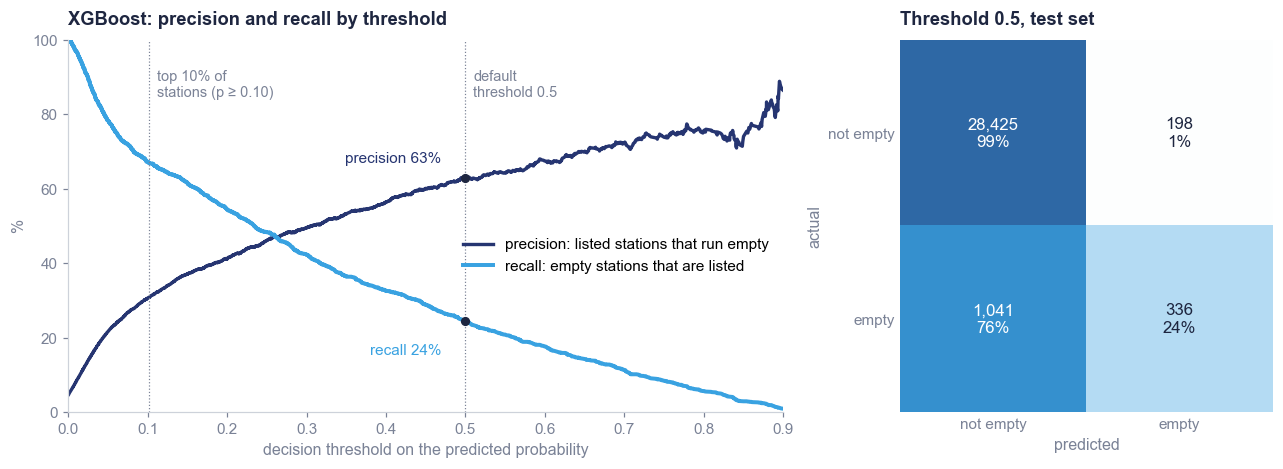

In [ ]:
# XGBoost, native API as in session 4.3 (same as the analysis notebook)
dtrain = xgb.DMatrix(X_train_e, label=y_train_e)
dtest = xgb.DMatrix(X_test_e, label=y_test_e)
params = {'objective': 'binary:logistic', 'max_depth': 4, 'eta': 0.3, 'seed': 42}
xgb_model = xgb.train(params, dtrain, 100)
y_proba_xgb = xgb_model.predict(dtest)
y_pred_xgb = (y_proba_xgb >= 0.5).astype(int)
fpr, tpr, _ = roc_curve(y_test_e, y_proba_xgb)
print('test AUC:', auc(fpr, tpr))

precision, recall, thr = precision_recall_curve(y_test_e, y_proba_xgb)
cut10 = np.sort(y_proba_xgb)[::-1][int(len(y_proba_xgb) * 0.10) - 1]

fig, axes = plt.subplots(1, 2, figsize=(12.1, 4.15), layout='constrained', width_ratios=[1.45, 1])
ax = axes[0]
ax.plot(thr, precision[:-1] * 100, color=NAVY, lw=2.2, label='precision: listed stations that run empty')
ax.plot(thr, recall[:-1] * 100, color=BLUE, lw=2.6, label='recall: empty stations that are listed')
for t, lab in [(0.5, 'default\nthreshold 0.5'), (cut10, f'top 10% of\nstations (p ≥ {cut10:.2f})')]:
    ax.axvline(t, color=GREY, lw=0.8, ls=':')
    ax.text(t + 0.01, 92, lab, fontsize=9.5, color=GREY, va='top')
p50, r50 = metrics.precision_score(y_test_e, y_pred_xgb) * 100, metrics.recall_score(y_test_e, y_pred_xgb) * 100
ax.plot([0.5, 0.5], [p50, r50], 'o', color=INK, ms=5)
ax.text(0.47, r50 - 9, f'recall {r50:.0f}%', fontsize=10, color=BLUE, ha='right')
ax.text(0.47, p50 + 4, f'precision {p50:.0f}%', fontsize=10, color=NAVY, ha='right')
ax.set_xlim(0, 0.9)
ax.set_ylim(0, 100)
ax.set_xlabel('decision threshold on the predicted probability')
ax.set_ylabel('%')
ax.legend(loc='center right', bbox_to_anchor=(1, 0.42))
ax.set_title('XGBoost: precision and recall by threshold')
ax = axes[1]
cm = confusion_matrix(y_test_e, y_pred_xgb)
ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap=blues, vmin=0, vmax=1.3)
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum() * 100
        ax.text(j, i, f'{cm[i, j]:,}\n{share:.0f}%', ha='center', va='center', fontsize=11, color='white' if share > 60 else INK)
ax.set_xticks([0, 1], ['not empty', 'empty'])
ax.set_yticks([0, 1], ['not empty', 'empty'])
ax.set_xlabel('predicted')
ax.set_ylabel('actual')
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title('Threshold 0.5, test set')
save(fig, 'pred_threshold')
numbers['xgb_cm'] = cm.tolist()
numbers['cut10'] = round(float(cut10), 3)
numbers['p50_r50'] = [round(p50, 1), round(r50, 1)]

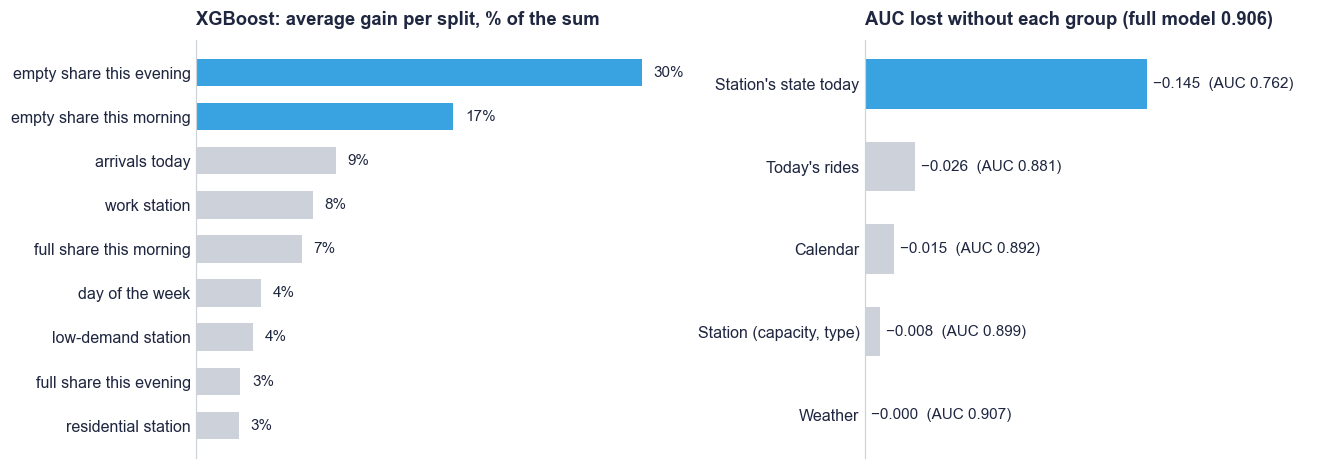

{"Station's state today": 0.7615, "Today's rides": 0.8808, 'Calendar': 0.8916, 'Station (capacity, type)': 0.8987, 'Weather': 0.9066} {'residential station': 2.9, 'full share this evening': 3.0, 'low-demand station': 3.9, 'day of the week': 4.4, 'full share this morning': 7.2, 'work station': 7.9, 'arrivals today': 9.5, 'empty share this morning': 17.5, 'empty share this evening': 30.3}


In [ ]:
# what drives the prediction: XGBoost importance (gain) and ablation (AUC lost when a group is removed)
nice_e = {'pct_empty_morning': 'empty share this morning', 'pct_full_morning': 'full share this morning', 'pct_empty_evening': 'empty share this evening',
          'pct_full_evening': 'full share this evening', 'departures': 'departures today', 'arrivals': 'arrivals today', 'net_flow_morning': 'net flow this morning',
          'capacity': 'capacity (docks)', 'tomorrow_weekday': 'day of the week', 'tomorrow_is_weekend': 'weekend tomorrow', 'tomorrow_holiday': 'holiday tomorrow',
          'tomorrow_tavg': 'temperature tomorrow', 'tomorrow_prcp': 'rain tomorrow', 'segment_Busy mixed': 'busy mixed station',
          'segment_Low demand / leisure': 'low-demand station', 'segment_Residential (morning departures)': 'residential station',
          'segment_Work (morning arrivals)': 'work station'}
gain = pd.Series(xgb_model.get_score(importance_type='gain'))
gain = (gain / gain.sum() * 100).rename(index=nice_e).sort_values().tail(9)

groups = {"Station's state today": ['pct_empty_morning', 'pct_full_morning', 'pct_empty_evening', 'pct_full_evening'],
          "Today's rides": ['departures', 'arrivals', 'net_flow_morning'],
          'Calendar': ['tomorrow_weekday', 'tomorrow_is_weekend', 'tomorrow_holiday'],
          'Station (capacity, type)': ['capacity'] + [c for c in X_e.columns if c.startswith('segment')],
          'Weather': ['tomorrow_tavg', 'tomorrow_prcp']}
full_auc = roc_auc = auc(fpr, tpr)
ablation = {}
for name, drop in groups.items():
    m = xgb.XGBClassifier(max_depth=4, learning_rate=0.3, n_estimators=100, random_state=42).fit(X_train_e.drop(columns=drop), y_train_e)
    f, t, _ = roc_curve(y_test_e, m.predict_proba(X_test_e.drop(columns=drop))[:, 1])
    ablation[name] = auc(f, t)
ablation = pd.Series(ablation)

fig, axes = plt.subplots(1, 2, figsize=(12.1, 4.15), layout='constrained', width_ratios=[1, 1])
ax = axes[0]
ax.barh(gain.index, gain.values, color=[BLUE if 'empty share' in n else LIGHT for n in gain.index], height=0.62)
for i, v in enumerate(gain.values):
    ax.text(v + 0.8, i, f'{v:.0f}%', va='center', fontsize=10, color=INK)
ax.set_xticks([])
ax.spines['bottom'].set_visible(False)
ax.tick_params(axis='y', length=0, labelcolor=INK, labelsize=10.5)
ax.set_title('XGBoost: average gain per split, % of the sum')
ax = axes[1]
loss = (full_auc - ablation).clip(lower=0).sort_values()
ax.barh(loss.index, loss.values, color=[BLUE if n == "Station's state today" else LIGHT for n in loss.index], height=0.6)
for i, (n, v) in enumerate(loss.items()):
    ax.text(v + 0.003, i, f'−{v:.3f}  (AUC {ablation[n]:.3f})', va='center', fontsize=10, color=INK)
ax.set_xlim(0, 0.24)
ax.set_xticks([])
ax.spines['bottom'].set_visible(False)
ax.tick_params(axis='y', length=0, labelcolor=INK, labelsize=10.5)
ax.set_title(f'AUC lost without each group (full model {full_auc:.3f})')
save(fig, 'pred_drivers')
numbers['ablation'] = ablation.round(4).to_dict()
numbers['gain'] = gain.round(1).to_dict()
print(numbers['ablation'], numbers['gain'])

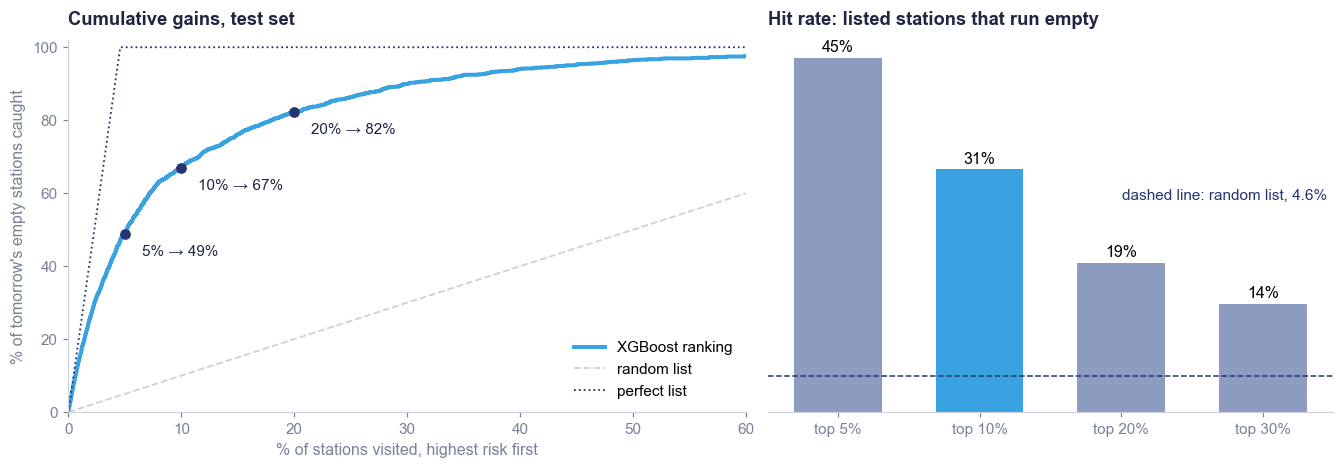

{5: np.float64(44.9), 10: np.float64(30.8), 20: np.float64(18.9), 30: np.float64(13.8)} 48.9 67.0 82.3


In [ ]:
# from probabilities to a truck list: cumulative gains and hit rate by list size
test_e = sample_e.loc[X_test_e.index].copy()
test_e['proba_empty'] = y_proba_xgb
ranked = test_e.sort_values('proba_empty', ascending=False)
caught = ranked['empty_tomorrow'].cumsum().values / ranked['empty_tomorrow'].sum() * 100
share = np.arange(1, len(ranked) + 1) / len(ranked) * 100
base = test_e['empty_tomorrow'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12.1, 4.15), layout='constrained', width_ratios=[1.2, 1])
ax = axes[0]
ax.plot(share, caught, color=BLUE, lw=2.6, label='XGBoost ranking')
ax.plot([0, 100], [0, 100], color=LIGHT, ls='--', lw=1.2, label='random list')
ax.plot([0, base, 100], [0, 100, 100], color=NAVY, ls=':', lw=1.2, label='perfect list')
for p in [5, 10, 20]:
    v = caught[int(len(ranked) * p / 100) - 1]
    ax.plot(p, v, 'o', color=NAVY, ms=6)
    ax.text(p + 1.5, v - 6, f'{p}% → {v:.0f}%', fontsize=10, color=INK)
    numbers[f'gain_{p}'] = round(v, 1)
ax.set_xlim(0, 60)
ax.set_ylim(0, 102)
ax.set_xlabel('% of stations visited, highest risk first')
ax.set_ylabel('% of tomorrow\'s empty stations caught')
ax.legend(loc='lower right')
ax.set_title('Cumulative gains, test set')
ax = axes[1]
sizes = [5, 10, 20, 30]
hit = [ranked.head(int(len(ranked) * p / 100))['empty_tomorrow'].mean() * 100 for p in sizes]
b = ax.bar(range(4), hit, color=[MUTED, BLUE, MUTED, MUTED], width=0.62)
ax.bar_label(b, fmt='%.0f%%', fontsize=10.5, padding=2)
ax.axhline(base, color=NAVY, ls='--', lw=1)
ax.text(3.45, 27, f'dashed line: random list, {base:.1f}%', ha='right', fontsize=10, color=NAVY)
ax.set_xticks(range(4), [f'top {p}%' for p in sizes])
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_title('Hit rate: listed stations that run empty')
save(fig, 'pred_gains')
numbers['hit'] = dict(zip(sizes, [round(h, 1) for h in hit]))
numbers['base'] = round(base, 2)
print(numbers['hit'], numbers['gain_5'], numbers['gain_10'], numbers['gain_20'])

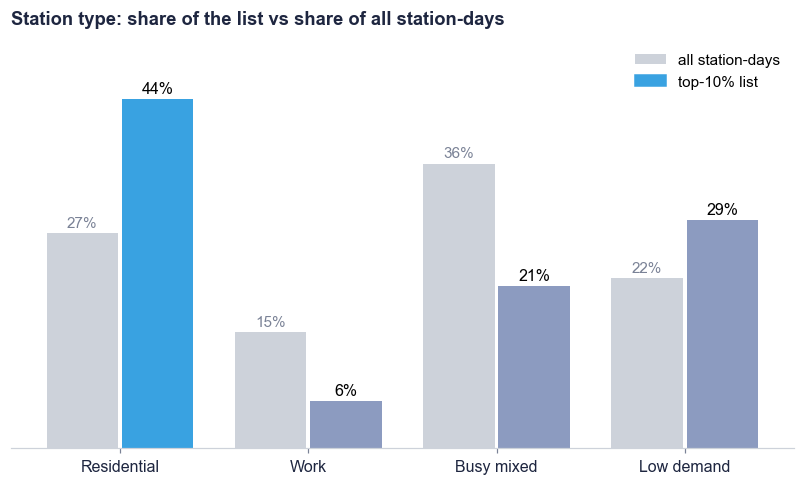

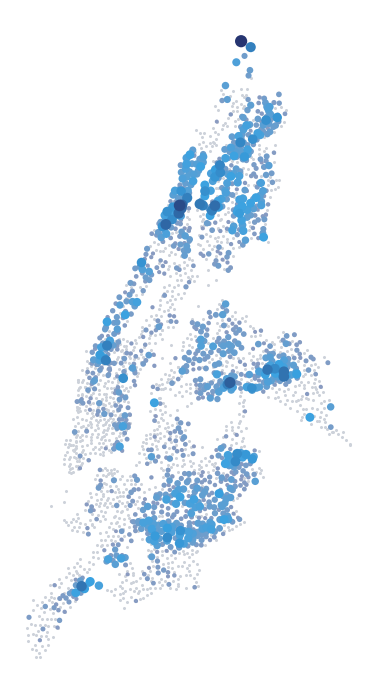

([['Residential', 27.3, 44.4],
  ['Work', 14.8, 6.0],
  ['Busy mixed', 36.2, 20.6],
  ['Low demand', 21.7, 29.0]],
 1080)

In [ ]:
# who is on the list, and where
top10 = ranked.head(int(len(ranked) * 0.10))
mix = pd.DataFrame({'all': test_e['seg'].value_counts(normalize=True) * 100, 'top10': top10['seg'].value_counts(normalize=True) * 100}).loc[seg_order]

fig, ax = plt.subplots(figsize=(7.2, 4.3), layout='constrained')
xx = np.arange(4)
b1 = ax.bar(xx - 0.2, mix['all'], 0.38, color=LIGHT, label='all station-days')
b2 = ax.bar(xx + 0.2, mix['top10'], 0.38, color=[BLUE, MUTED, MUTED, MUTED], label='top-10% list')
ax.bar_label(b1, fmt='%.0f%%', fontsize=10, padding=2, color=GREY)
ax.bar_label(b2, fmt='%.0f%%', fontsize=10.5, padding=2)
ax.set_xticks(xx, seg_order)
ax.tick_params(axis='x', labelcolor=INK, labelsize=10.5)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_ylim(0, 52)
ax.legend(loc='upper right', handles=[b1, plt.Rectangle((0, 0), 1, 1, color=BLUE)], labels=['all station-days', 'top-10% list'])
ax.set_title('Station type: share of the list vs share of all station-days')
save(fig, 'pred_mix')

flag = test_e.assign(listed=test_e['proba_empty'] >= cut10).groupby('station_name')['listed'].mean()
st = stations.set_index('station_name').join(flag.rename('listed')).fillna({'listed': 0})
fig, ax = plt.subplots(figsize=(7, 8))
ax.scatter(st['lng'], st['lat'], s=4, color=LIGHT, linewidths=0)
hot = st[st['listed'] > 0].sort_values('listed')
ax.scatter(hot['lng'], hot['lat'], s=4 + hot['listed'] * 60, c=hot['listed'], cmap=LinearSegmentedColormap.from_list('b', [MUTED, BLUE, NAVY]), linewidths=0)
ax.set_aspect(1.32)
ax.axis('off')
plt.savefig('charts/map_list.png', dpi=250, transparent=True, bbox_inches='tight', pad_inches=0)
plt.show()
numbers['mix'] = mix.round(1).reset_index().values.tolist()
numbers['stations_ever_listed'] = int((st['listed'] > 0).sum())
numbers['mix'], numbers['stations_ever_listed']

## 6b. Night by night: the model against a simple rule, and where to collect bikes

In [ ]:
dates = pd.Series(data['date'].unique())
test_dates = dates.sample(frac=0.2, random_state=42)
is_test = data['date'].isin(test_dates)
X_night = pd.get_dummies(data[features_e], columns=['segment'], dtype='int')
night_model = xgb.XGBClassifier(max_depth=4, learning_rate=0.3, n_estimators=100, random_state=42)
night_model.fit(X_night[~is_test], data.loc[~is_test, 'empty_tomorrow'])
nights = data[is_test].copy()
nights['proba_empty'] = night_model.predict_proba(X_night[is_test])[:, 1]

def nightly_list(score, share):
    caught, total, listed_n, per_night = 0, 0, 0, []
    for date, night in nights.groupby('date'):
        k = int(round(len(night) * share))
        listed = night.sort_values(score, ascending=False, kind='mergesort').head(k)
        caught += listed['empty_tomorrow'].sum()
        total += night['empty_tomorrow'].sum()
        listed_n += k
        per_night.append(listed['empty_tomorrow'].sum() / max(night['empty_tomorrow'].sum(), 1))
    return caught / total, caught / listed_n, per_night

bench = {}
for share in [0.05, 0.10, 0.20]:
    for name, score in [('model', 'proba_empty'), ('rule_day', 'pct_empty_day'), ('rule_evening', 'pct_empty_evening')]:
        bench[(share, name)] = nightly_list(score, share)
numbers['night_auc'] = {'model': round(metrics.roc_auc_score(nights['empty_tomorrow'], nights['proba_empty']), 3),
                        'rule_day': round(metrics.roc_auc_score(nights['empty_tomorrow'], nights['pct_empty_day']), 3)}
numbers['bench'] = {f'{int(sh * 100)}_{n}': [round(v[0] * 100, 1), round(v[1] * 100, 1)] for (sh, n), v in bench.items()}
numbers['bench_exact'] = {f'{int(sh * 100)}_{n}': round(v[0] * 100, 3) for (sh, n), v in bench.items()}
numbers['test_nights'] = int(nights['date'].nunique())
numbers['night_base'] = round(nights['empty_tomorrow'].mean() * 100, 1)
m10, r10 = bench[(0.10, 'model')][2], bench[(0.10, 'rule_day')][2]
numbers['nights_model_better'] = int(sum(a > b for a, b in zip(m10, r10)))
numbers['bench'], numbers['night_auc'], numbers['nights_model_better']

({'5_model': [np.float64(42.5), np.float64(41.9)],
  '5_rule_day': [np.float64(32.6), np.float64(32.2)],
  '5_rule_evening': [np.float64(31.4), np.float64(31.0)],
  '10_model': [np.float64(62.1), np.float64(30.6)],
  '10_rule_day': [np.float64(51.5), np.float64(25.4)],
  '10_rule_evening': [np.float64(47.8), np.float64(23.6)],
  '20_model': [np.float64(79.4), np.float64(19.6)],
  '20_rule_day': [np.float64(75.5), np.float64(18.6)],
  '20_rule_evening': [np.float64(63.2), np.float64(15.6)]},
 {'model': np.float64(0.905), 'rule_day': np.float64(0.855)},
 68)

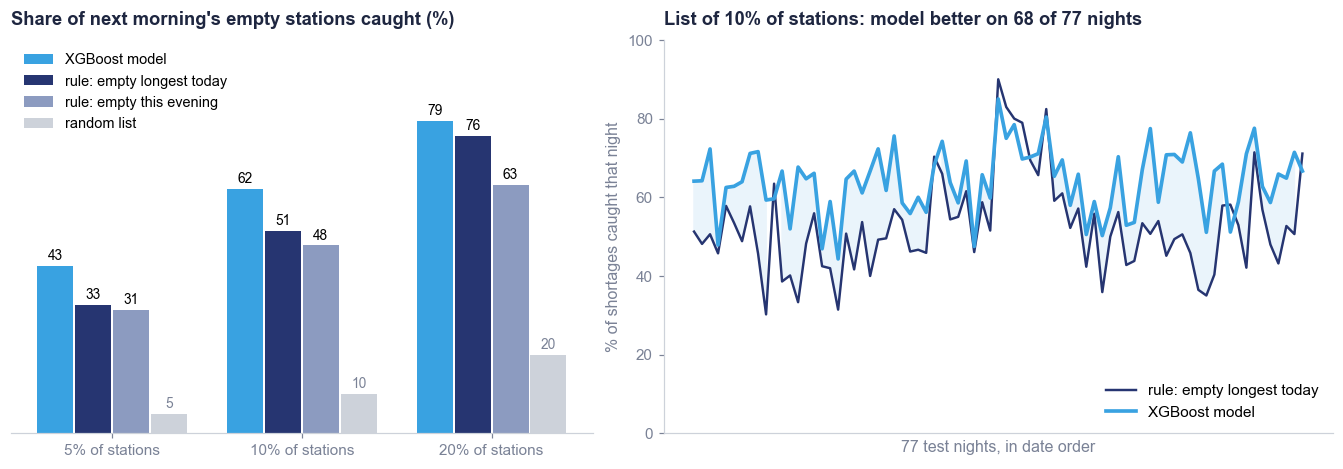

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.1, 4.15), layout='constrained', width_ratios=[1, 1.15])
ax = axes[0]
groups = [('model', 'XGBoost model', BLUE), ('rule_day', 'rule: empty longest today', NAVY), ('rule_evening', 'rule: empty this evening', MUTED)]
xx = np.arange(3)
for i, (key, lab, c) in enumerate(groups):
    vals = [bench[(sh, key)][0] * 100 for sh in [0.05, 0.10, 0.20]]
    b = ax.bar(xx + (i - 1.5) * 0.2, vals, 0.19, color=c, label=lab)
    ax.bar_label(b, fmt='%.0f', fontsize=9, padding=2)
b = ax.bar(xx + 1.5 * 0.2, [5, 10, 20], 0.19, color=LIGHT, label='random list')
ax.bar_label(b, fmt='%.0f', fontsize=9, padding=2, color=GREY)
ax.set_xticks(xx, ['5% of stations', '10% of stations', '20% of stations'])
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_ylim(0, 100)
ax.legend(loc='upper left', fontsize=9.5)
ax.set_title("Share of next morning's empty stations caught (%)")
ax = axes[1]
xn = np.arange(len(m10))
ax.plot(xn, np.array(r10) * 100, color=NAVY, lw=1.6, label='rule: empty longest today')
ax.plot(xn, np.array(m10) * 100, color=BLUE, lw=2.4, label='XGBoost model')
ax.fill_between(xn, np.array(r10) * 100, np.array(m10) * 100, where=np.array(m10) > np.array(r10), color=TINT)
ax.set_xticks([])
ax.set_xlabel(f'{len(m10)} test nights, in date order')
ax.set_ylabel('% of shortages caught that night')
ax.set_ylim(0, 100)
ax.legend(loc='lower right')
ax.set_title(f"List of 10% of stations: model better on {numbers['nights_model_better']} of {len(m10)} nights")
save(fig, 'pred_bench')

In [ ]:
full_tomorrow = station_day[['station_name', 'date', 'pct_full_morning']].copy()
full_tomorrow['date'] = full_tomorrow['date'] - pd.Timedelta(days=1)
full_tomorrow.columns = ['station_name', 'date', 'tomorrow_pct_full_morning']
nights = nights.merge(full_tomorrow, on=['station_name', 'date'], how='left')
nights['full_tomorrow'] = (nights['tomorrow_pct_full_morning'] >= 33).astype(int)
dropoff = nights.groupby('date', group_keys=False).apply(lambda n: n.nlargest(int(round(len(n) * 0.10)), 'proba_empty'))
full_tonight = nights[nights['pct_full_evening'] >= 33]
pickup = full_tonight[full_tonight['proba_empty'] <= full_tonight['proba_empty'].median()]
lists = {'drop-off list': dropoff, 'full this evening': full_tonight, 'pick-up list': pickup, 'all stations': nights}
outcome = pd.DataFrame({'per_night': [len(x) / nights['date'].nunique() for x in lists.values()],
                        'empty': [x['empty_tomorrow'].mean() * 100 for x in lists.values()],
                        'full': [x['full_tomorrow'].mean() * 100 for x in lists.values()]}, index=lists.keys())
mix_plan = pd.DataFrame({n: x['seg'].value_counts(normalize=True) * 100 for n, x in lists.items()}).loc[seg_order]
numbers['plan_outcome'] = outcome.round(1).reset_index().values.tolist()
numbers['plan_mix'] = mix_plan.round(1).reset_index().values.tolist()
outcome.round(1), mix_plan.round(1)

(                   per_night  empty  full
 drop-off list          214.8   30.6   0.7
 full this evening      134.5    1.0  38.9
 pick-up list            67.3    0.1  52.5
 all stations          2148.0    4.9   6.8,
              drop-off list  full this evening  pick-up list  all stations
 seg                                                                      
 Residential           42.5               15.6          17.7          27.7
 Work                   6.0                9.9          11.8          14.6
 Busy mixed            18.3               46.7          39.3          36.3
 Low demand            33.2               27.9          31.2          21.4)

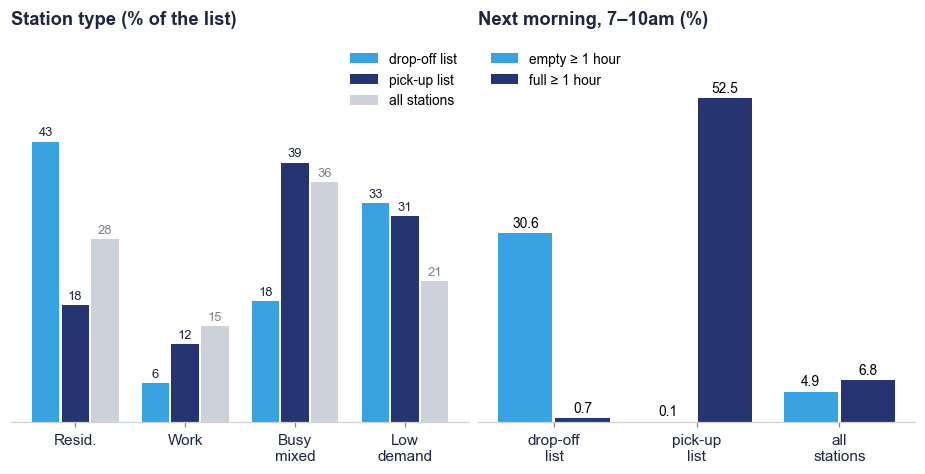

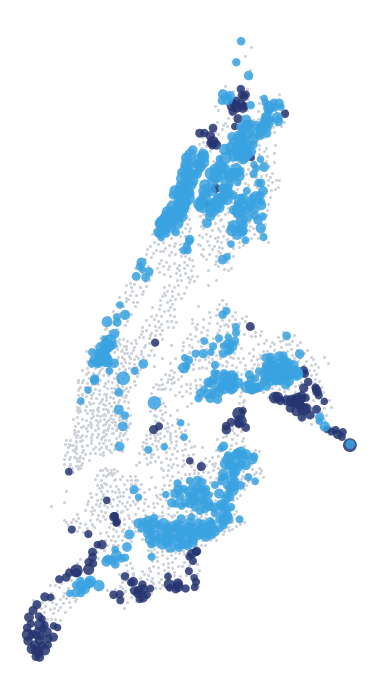

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8.3, 4.2), layout='constrained', width_ratios=[1.05, 1])
ax = axes[0]
xx = np.arange(4)
for i, (n, c) in enumerate([('drop-off list', BLUE), ('pick-up list', NAVY), ('all stations', LIGHT)]):
    b = ax.bar(xx + (i - 1) * 0.27, mix_plan[n], 0.25, color=c, label=n)
    ax.bar_label(b, fmt='%.0f', fontsize=8.5, padding=2, color=GREY if n == 'all stations' else INK)
ax.set_xticks(xx, ['Resid.', 'Work', 'Busy\nmixed', 'Low\ndemand'])
ax.tick_params(axis='x', labelcolor=INK)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_ylim(0, 58)
ax.legend(loc='upper right', fontsize=9)
ax.set_title('Station type (% of the list)')
ax = axes[1]
cats = ['drop-off list', 'pick-up list', 'all stations']
xx = np.arange(3)
b1 = ax.bar(xx - 0.2, outcome.loc[cats, 'empty'], 0.38, color=BLUE, label='empty ≥ 1 hour')
b2 = ax.bar(xx + 0.2, outcome.loc[cats, 'full'], 0.38, color=NAVY, label='full ≥ 1 hour')
ax.bar_label(b1, fmt='%.1f', fontsize=9, padding=2)
ax.bar_label(b2, fmt='%.1f', fontsize=9, padding=2)
ax.set_xticks(xx, ['drop-off\nlist', 'pick-up\nlist', 'all\nstations'])
ax.tick_params(axis='x', labelcolor=INK)
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_ylim(0, 62)
ax.legend(loc='upper left', fontsize=9)
ax.set_title('Next morning, 7–10am (%)')
save(fig, 'plan_lists')

freq_drop = nights.assign(on=nights.index.isin(dropoff.index)).groupby('station_name')['on'].mean()
freq_pick = nights.assign(on=nights.index.isin(pickup.index)).groupby('station_name')['on'].mean()
st = stations.set_index('station_name').join(freq_drop.rename('drop')).join(freq_pick.rename('pick')).fillna(0)
fig, ax = plt.subplots(figsize=(7, 8))
ax.scatter(st['lng'], st['lat'], s=4, color=LIGHT, linewidths=0)
p = st[st['pick'] > 0.15]
ax.scatter(p['lng'], p['lat'], s=6 + p['pick'] * 120, color=NAVY, alpha=0.85, linewidths=0)
d = st[st['drop'] > 0.15]
ax.scatter(d['lng'], d['lat'], s=6 + d['drop'] * 120, color=BLUE, alpha=0.85, linewidths=0)
ax.set_aspect(1.32)
ax.axis('off')
plt.savefig('charts/map_plan.png', dpi=250, transparent=True, bbox_inches='tight', pad_inches=0)
plt.show()
numbers['map_plan_counts'] = [int((st['drop'] > 0.15).sum()), int((st['pick'] > 0.15).sum())]

## 7. Stress test: train on Aug–Oct 2025, test month by month

In [ ]:
X_all = pd.get_dummies(data[features_e], columns=['segment'], dtype='int')
y_all = data['empty_tomorrow']
train_mask = (data['date'] >= '2025-08-01') & (data['date'] < '2025-11-01')
stress_model = xgb.XGBClassifier(max_depth=4, learning_rate=0.3, n_estimators=100, random_state=42).fit(X_all[train_mask], y_all[train_mask])

reg_all = station_day.dropna(subset=['departures_last_week', 'tavg', 'prcp']).copy()
reg_all['log_departures'] = np.log1p(reg_all['departures'])
reg_all['log_departures_last_week'] = np.log1p(reg_all['departures_last_week'])
X_reg_all = pd.get_dummies(reg_all[['weekday', 'holiday', 'tavg', 'prcp', 'wspd', 'capacity', 'segment', 'log_departures_last_week']],
                           columns=['weekday', 'segment'], drop_first=True, dtype='int')
y_reg_all = reg_all['log_departures']
reg_train = (reg_all['date'] >= '2025-08-01') & (reg_all['date'] < '2025-11-01')
stress_reg = LinearRegression().fit(X_reg_all[reg_train], y_reg_all[reg_train])

monthly = []
for p in pd.period_range('2025-08', '2026-08', freq='M'):
    m1 = data['date'].dt.to_period('M') == p
    m2 = reg_all['date'].dt.to_period('M') == p
    f, t, _ = roc_curve(y_all[m1], stress_model.predict_proba(X_all[m1])[:, 1])
    monthly.append([p, auc(f, t), stress_reg.score(X_reg_all[m2], y_reg_all[m2]), y_all[m1].mean() * 100])
monthly = pd.DataFrame(monthly, columns=['month', 'auc', 'r2', 'base']).set_index('month')
monthly.round(3)

,auc,r2,base
month,,,
2025-08,0.912,0.909,2.997
2025-09,0.906,0.911,4.149
2025-10,0.913,0.896,3.608
2025-11,0.892,0.867,5.377
2025-12,0.913,0.727,6.578
2026-01,0.916,0.628,6.752
2026-02,0.913,0.695,7.702
2026-03,0.891,0.759,6.903
2026-04,0.895,0.828,5.331


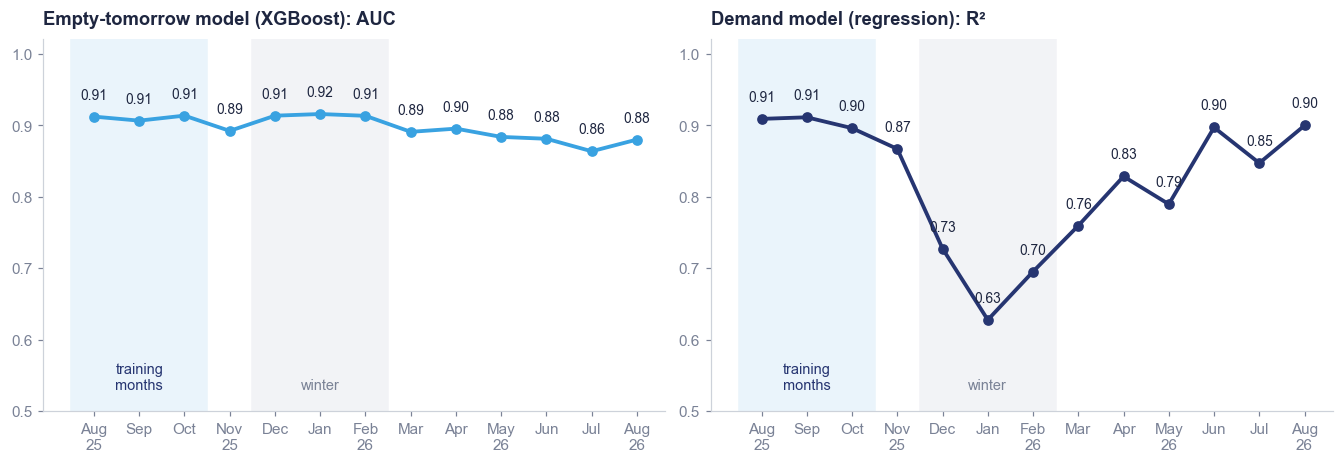

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12.1, 4.1), layout='constrained')
labels_m = [p.strftime('%b\n%y') if p.month in (8, 11, 2, 5) else p.strftime('%b') for p in monthly.index]
for ax, col, title, c in [(axes[0], 'auc', 'Empty-tomorrow model (XGBoost): AUC', BLUE), (axes[1], 'r2', 'Demand model (regression): R²', NAVY)]:
    ax.axvspan(-0.5, 2.5, color=TINT)
    ax.text(1, 0.53, 'training\nmonths', ha='center', fontsize=9.5, color=NAVY)
    ax.axvspan(3.5, 6.5, color='#F2F3F6')
    ax.text(5, 0.53, 'winter', ha='center', fontsize=9.5, color=GREY)
    ax.plot(range(len(monthly)), monthly[col], color=c, lw=2.5, marker='o', ms=6)
    for i, v in enumerate(monthly[col]):
        ax.text(i, v + 0.025, f'{v:.2f}', ha='center', fontsize=9, color=INK)
    ax.set_xticks(range(len(monthly)), labels_m)
    ax.set_ylim(0.5, 1.02)
    ax.set_title(title)
save(fig, 'robust_monthly')
numbers['monthly'] = monthly.round(3).reset_index().astype(str).values.tolist()

## 8. App reviews: LDA

In [ ]:
import nltk
from nltk.corpus import stopwords
from nltk.stem.wordnet import WordNetLemmatizer
import string
import gensim
from gensim import corpora
from gensim.models import CoherenceModel

stop = set(stopwords.words('english'))
exclude = set(string.punctuation)
lemma = WordNetLemmatizer()

def clean(doc):
    stop_free = " ".join([i for i in doc.lower().split() if i not in stop])
    punc_free = ''.join(ch for ch in stop_free if ch not in exclude)
    normalized = " ".join(lemma.lemmatize(word) for word in punc_free.split())
    return normalized

doc_clean = [clean(doc).split() for doc in (reviews['title'].fillna('') + ' ' + reviews['content']).tolist()]
dictionary = corpora.Dictionary(doc_clean)
dictionary.filter_extremes(no_below=5, no_above=0.5)
doc_term_matrix = [dictionary.doc2bow(doc) for doc in doc_clean]
Lda = gensim.models.ldamodel.LdaModel

coherence = {}
for n in range(2, 9):
    m = Lda(doc_term_matrix, num_topics=n, id2word=dictionary, passes=10, random_state=42)
    coherence[n] = CoherenceModel(model=m, texts=doc_clean, dictionary=dictionary, coherence='c_v').get_coherence()
lda_model = Lda(doc_term_matrix, num_topics=4, id2word=dictionary, passes=10, random_state=42)
topic_names = {0: 'Docks & stations', 1: 'Customer service', 2: 'Pricing & charges', 3: 'App & map'}
main_topic = [max(lda_model.get_document_topics(bow, minimum_probability=0), key=lambda x: x[1])[0] for bow in doc_term_matrix]
reviews['topic'] = pd.Series(main_topic).map(topic_names)
summary = reviews.groupby('topic').agg(reviews=('rating', 'size'), rating=('rating', 'mean'))
coherence, summary

({2: np.float64(0.32801441669908393),
  3: np.float64(0.29373021455687853),
  4: np.float64(0.3617173356168955),
  5: np.float64(0.3231188590704159),
  6: np.float64(0.302664605795153),
  7: np.float64(0.32180487415497455),
  8: np.float64(0.30190443885564866)},
                    reviews    rating
 topic                               
 App & map              173  1.832370
 Customer service       170  1.376471
 Docks & stations        98  1.622449
 Pricing & charges       59  1.355932)

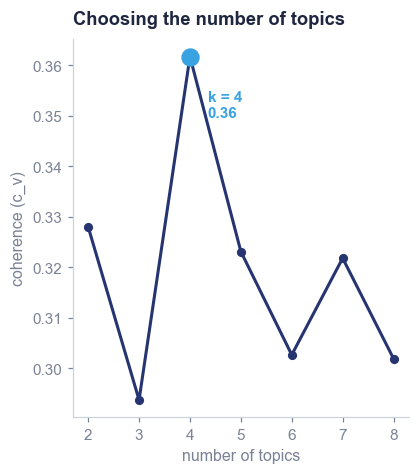

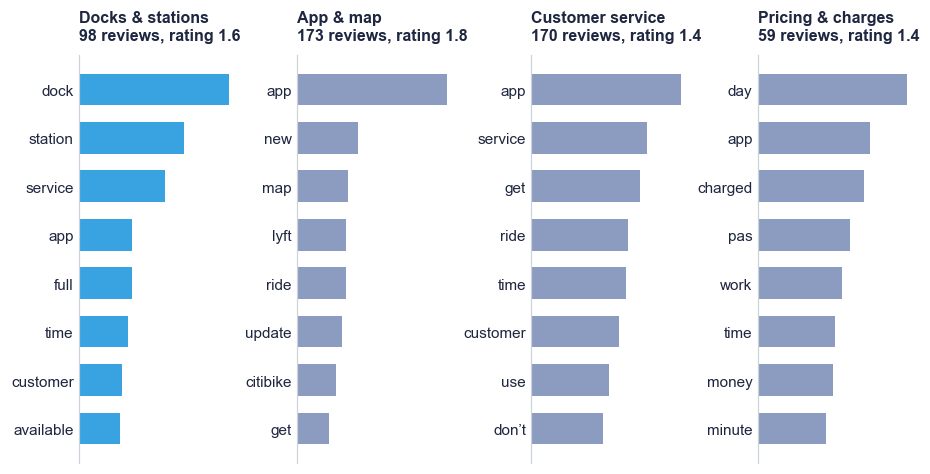

In [ ]:
fig, ax = plt.subplots(figsize=(3.7, 4.2), layout='constrained')
ax.plot(list(coherence.keys()), list(coherence.values()), color=NAVY, lw=2, marker='o', ms=5)
ax.plot(4, coherence[4], 'o', color=BLUE, ms=11)
ax.text(4.35, coherence[4] - 0.012, f'k = 4\n{coherence[4]:.2f}', fontsize=10, color=BLUE, fontweight='bold')
ax.set_xlabel('number of topics')
ax.set_ylabel('coherence (c_v)')
ax.set_title('Choosing the number of topics')
save(fig, 'lda_coherence')

order = ['Docks & stations', 'App & map', 'Customer service', 'Pricing & charges']
ids = {v: k for k, v in topic_names.items()}
fig, axes = plt.subplots(1, 4, figsize=(8.3, 4.2), layout='constrained')
for ax, name in zip(axes, order):
    words = lda_model.show_topic(ids[name], topn=8)[::-1]
    ax.barh([w for w, _ in words], [p * 100 for _, p in words], color=BLUE if name == 'Docks & stations' else MUTED, height=0.65)
    ax.set_xticks([])
    ax.spines['bottom'].set_visible(False)
    ax.tick_params(axis='y', length=0, labelcolor=INK, labelsize=10)
    ax.set_title(f"{name}\n{summary.loc[name, 'reviews']} reviews, rating {summary.loc[name, 'rating']:.1f}", fontsize=10.5)
save(fig, 'lda_topics')
numbers['coherence'] = {k: round(v, 3) for k, v in coherence.items()}
numbers['topics'] = summary.round(2).reset_index().values.tolist()
numbers['mean_rating'] = round(reviews['rating'].mean(), 2)

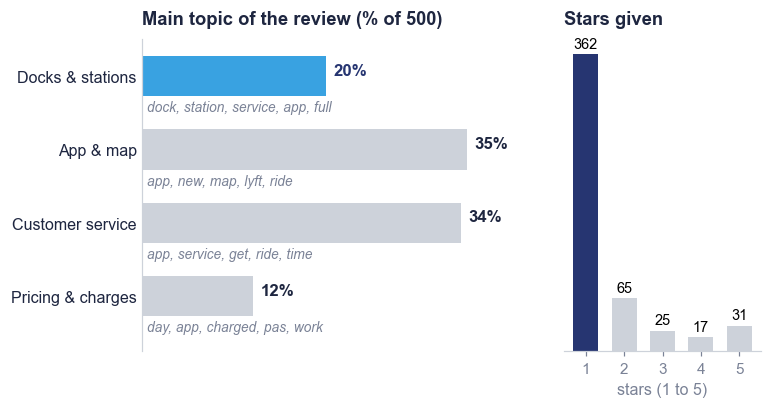

In [ ]:
# reviews for the problem section: share of reviews by main topic (with the topic's most likely words) and distribution of ratings
fig, axes = plt.subplots(1, 2, figsize=(6.9, 3.6), layout='constrained', width_ratios=[2.1, 1])
ax = axes[0]
order = ['Pricing & charges', 'Customer service', 'App & map', 'Docks & stations']
share = [summary.loc[n, 'reviews'] / len(reviews) * 100 for n in order]
ax.barh(order, share, color=[BLUE if n == 'Docks & stations' else LIGHT for n in order], height=0.55)
for i, n in enumerate(order):
    words = ', '.join(w for w, _ in lda_model.show_topic(ids[n], topn=5))
    ax.text(share[i] + 0.8, i + 0.08, f'{share[i]:.0f}%', va='center', fontsize=11, fontweight='bold', color=NAVY if n == 'Docks & stations' else INK)
    ax.text(0.5, i - 0.43, words, va='center', fontsize=9, color=GREY, style='italic')
ax.set_xlim(0, 44)
ax.set_ylim(-0.75, 3.5)
ax.set_xticks([])
ax.spines['bottom'].set_visible(False)
ax.tick_params(axis='y', length=0, labelcolor=INK, labelsize=10.5)
ax.set_title('Main topic of the review (% of 500)')
ax = axes[1]
stars = reviews['rating'].value_counts().sort_index()
b = ax.bar(stars.index, stars.values, color=[NAVY if s == 1 else LIGHT for s in stars.index], width=0.65)
ax.bar_label(b, fontsize=9.5, padding=2)
ax.set_xticks(range(1, 6))
ax.set_xlabel('stars (1 to 5)')
ax.set_yticks([])
ax.spines['left'].set_visible(False)
ax.set_title('Stars given')
save(fig, 'reviews_main')
numbers['stars'] = {int(k): int(v) for k, v in stars.items()}
numbers['review_dates'] = [str(reviews['date'].min())[:10], str(reviews['date'].max())[:10]]

In [ ]:
# numbers quoted on the slides
numbers

{'empty_peak': [11, np.float64(6.3)],
 'empty_6am': np.float64(2.9),
 'rides_max': ['2026-08-15', 207734],
 'rides_min': ['2026-01-26', 5749],
 'rides_per_day': 128159,
 'peak_hour_rides': 13651,
 'top10_share': np.float64(38.5),
 'top25_share': np.float64(69.2),
 'net_flow_lose': 277,
 'net_flow_gain': 265,
 'median_duration_member': 8.4,
 'median_duration_casual': 12.7,
 'median_km_member': 1.47,
 'median_km_casual': 1.73,
 'top10_empty_share': np.float64(46.5),
 'stations_never_empty': np.float64(35.4),
 'empty_1h_share': np.float64(4.7),
 'empty_by_month': {'2025-08': 3.0,
  '2025-09': 4.1,
  '2025-10': 3.7,
  '2025-11': 5.2,
  '2025-12': 6.8,
  '2026-01': 6.5,
  '2026-02': 7.8,
  '2026-03': 6.8,
  '2026-04': 5.5,
  '2026-05': 3.7,
  '2026-06': 3.5,
  '2026-07': 2.3,
  '2026-08': 2.7},
 'strata_n': 26,
 'sample_max_month': ['2026-06', 21455],
 'sample_min_month': ['2026-02', 4839],
 'sample_casual': 36047,
 'silhouette': [np.float64(0.15),
  np.float64(0.129),
  np.float64(0.112),
